# 🎓 Asistente de Inteligencia Artificial para la Planificación Docente
### Predicción Temprana de Resultados Académicos y Motor de Recomendaciones Pedagógicas Basado en el Dataset OULAD

---

## Portada Académica Institucional

| Campo Institucional | Información Oficial |
| :--- | :--- |
| **Institución** | Universidad Federico Henríquez y Carvajal (**UFHEC**) |
| **Programa de Posgrado** | Maestría en Inteligencia Artificial Aplicada a la Educación e Investigación |
| **Asignatura** | Aprendizaje Automático (*Machine Learning*) |
| **Código de Asignatura** | `IAE-2501` |
| **Docente Titular** | Mtro. Feibert Guzmán |
| **Estudiante / Autora** | **Jhessika Lidabed Espaillat Espaillat** |
| **Fecha de Entrega** | Noviembre de 2026 |

---

## Tabla de Contenido Metodológica

1. **[Etapa 1. Presentación del Proyecto](#etapa-1)**
   - 1.1. Introducción y contextualización
   - 1.2. Planteamiento del problema
   - 1.3. Justificación académica y pedagógica
   - 1.4. Objetivo general y objetivos específicos
   - 1.5. Preguntas de investigación
   - 1.6. Descripción general del dataset OULAD
   - 1.7. Alcance y limitaciones del estudio
2. **[Etapa 2. Ingesta de Datos](#etapa-2)**
   - 2.1. Verificación del entorno e importación de librerías
   - 2.2. Identificación y carga de archivos CSV del repositorio OULAD
   - 2.3. Validación de dimensiones, estructura y tipos de datos
   - 2.4. Diccionario y descripción de variables originales
3. **[Etapa 3. Extracción, Carga y Transformación (ETL/ELT Sin Fuga de Información)](#etapa-3)**
   - 3.1. Limpieza, auditoría de duplicados y análisis de valores faltantes
   - 3.2. Formulación de la variable objetivo binaria (`target`)
   - 3.3. Prevención de fuga de información (*Data Leakage*): partición previa al preprocesamiento
   - 3.4. Diseño del `ColumnTransformer` (imputación, escalado y codificación One-Hot)
4. **[Etapa 4. Análisis Exploratorio de Datos (EDA)](#etapa-4)**
   - 4.1. Estadísticas descriptivas y distribución de resultados académicos
   - 4.2. Impacto de los intentos previos (`num_of_prev_attempts`)
   - 4.3. Análisis de créditos estudiados (`studied_credits`) y nivel educativo (`highest_education`)
   - 4.4. Gradiente socioeconómico (`imd_band`) y matriz de correlación
5. **[Etapa 5. Perfilado Automático con YData Profiling](#etapa-5)**
   - 5.1. Generación del informe interactivo HTML y hallazgos de calidad de datos
6. **[Etapa 6. Preparación del Modelo](#etapa-6)**
   - 6.1. Validación de matrices transformadas, control de reproducibilidad y justificación metodológica
7. **[Etapa 7. Entrenamiento de Modelos Supervisados](#etapa-7)**
   - 7.1. Modelo principal: `RandomForestClassifier`
   - 7.2. Modelos comparativos: `LogisticRegression` y `DecisionTreeClassifier`
8. **[Etapa 8. Evaluación Exhaustiva y Validación](#etapa-8)**
   - 8.1. Métricas en el conjunto de prueba (`Accuracy`, `Precision`, `Recall`, `F1`, `Balanced Accuracy`, `ROC-AUC`)
   - 8.2. Análisis de matrices de confusión y errores críticos en contextos educativos
   - 8.3. Validación Cruzada Estratificada (5-Fold) y Evaluación por Cohorte Temporal (`2014J`)
   - 8.4. Importancia de variables (*Feature Importance*)
9. **[Etapa 9. Predicción para Nuevos Estudiantes](#etapa-9)**
   - 9.1. Inferencia estandarizada mediante pipeline serializado sin relleno arbitrario de ceros
10. **[Etapa 10. Motor de Recomendaciones Pedagógicas Basado en Reglas Explícitas](#etapa-10)**
    - 10.1. Distinción arquitectónica entre predicción estadística y prescripción pedagógica
    - 10.2. Evaluación en las 7 dimensiones de planificación docente
11. **[Etapa 11. Conclusiones, Limitaciones y Referencias APA 7](#etapa-11)**

<a id="etapa-1"></a>
## Etapa 1. Presentación del Proyecto

### 1.1. Introducción y Contextualización
La transformación digital de la educación superior ha generado volúmenes sin precedentes de información académica, demográfica y conductual en los sistemas de gestión del aprendizaje (*Learning Management Systems* — LMS). Sin embargo, en la práctica docente cotidiana, la planificación pedagógica suele apoyarse en evaluaciones sumativas tardías: cuando el docente detecta que un estudiante reprueba o abandona la asignatura, el margen de maniobra para intervenir pedagógicamente ya se ha reducido de forma crítica.

El proyecto **«Asistente de Inteligencia Artificial para la Planificación Docente»** integra técnicas de **Aprendizaje Automático Supervisado (*Supervised Machine Learning*)** con un **motor explícito de reglas pedagógicas** para asistir al profesorado en la identificación temprana de estudiantes con alta probabilidad de fracaso académico o retiro, traduciendo las estimaciones probabilísticas en acciones concretas de acompañamiento instruccional.

---

### 1.2. Planteamiento del Problema
En las instituciones de educación superior —tanto en modalidades a distancia como semipresenciales y presenciales—, las tasas de reprobación y deserción representan un problema estructural que afecta la trayectoria vital del estudiante y la eficiencia académica institucional. En el conjunto de datos **Open University Learning Analytics Dataset (OULAD)**, de un total de `32,593` matrículas registradas en la tabla `studentInfo.csv`, **`17,208` estudiantes (`52.80%`) culminan en fracaso (`Fail`, `21.64%`) o retiro formal (`Withdrawn`, `31.16%`)**, mientras que solo `15,385` (`47.20%`) logran aprobar (`Pass`, `37.93%`) o alcanzar distinción (`Distinction`, `9.28%`).

El problema central radica en que el cuerpo docente carece de herramientas analíticas accesibles que permitan:
1. Estimar desde el inicio del periodo académico la vulnerabilidad de cada estudiante ante el fracaso o abandono.
2. Articular dicha estimación con estrategias diferenciadas de tutoría, refuerzo, evaluación formativa y ajuste de la carga académica.

---

### 1.3. Justificación
El desarrollo de este prototipo se justifica en tres dimensiones complementarias:
- **Pedagógica:** Facilita la transición desde un modelo docente reactivo (basado únicamente en calificaciones finales) hacia una **planificación docente preventiva e inclusiva**, alineada con el Diseño Universal para el Aprendizaje (DUA).
- **Científico-Metodológica:** Aplica rigurosamente el estándar **CRISP-ML(Q)**, implementando flujos de preprocesamiento encapsulados en `Pipeline` y `ColumnTransformer` que garantizan cero fuga de información (*Data Leakage*), validación cruzada estratificada y validación temporal inter-cohorte.
- **Social e Institucional:** Contribuye directamente a la permanencia estudiantil y al uso ético, transparente y auditable de la inteligencia artificial en la educación superior.

---

### 1.4. Objetivo General y Objetivos Específicos

#### Objetivo General
Desarrollar un **Asistente de Inteligencia Artificial para la Planificación Docente** basado en modelos de aprendizaje automático supervisado (con **Random Forest Classifier** como modelo principal) y un motor de reglas pedagógicas explícitas sobre el dataset **OULAD**, capaz de estimar tempranamente el riesgo de fracaso o retiro estudiantil y generar recomendaciones orientativas para la intervención docente.

#### Objetivos Específicos
1. Ejecutar un proceso reproducible de ingesta, limpieza, imputación, escalado y codificación de variables (*ETL/ELT*) sobre los `32,593` registros de `studentInfo.csv`, previniendo cualquier fuga de información entre entrenamiento y prueba.
2. Analizar los factores académicos y sociodemográficos asociados al éxito y al fracaso estudiantil mediante un Análisis Exploratorio de Datos (EDA) y un perfilado automatizado con **YData Profiling**.
3. Entrenar, ajustar y comparar el modelo principal **Random Forest Classifier** frente a **Logistic Regression** y **Decision Tree Classifier**, evaluando su desempeño mediante `Accuracy`, `Precision`, `Recall`, `F1-score`, `Balanced Accuracy`, `ROC-AUC`, validación cruzada de 5 pliegues y evaluación temporal en la cohorte `2014J`.
4. Diseñar un motor determinista de recomendaciones pedagógicas en siete dimensiones docentes, diferenciando explícitamente la inferencia estadística del modelo respecto de las reglas pedagógicas.
5. Desplegar los resultados en una aplicación web modular en **Streamlit** y una landing page académica para **GitHub Pages**, incorporando salvaguardas éticas sobre la incertidumbre predictiva.

---

### 1.5. Preguntas de Investigación
1. **PI-1:** ¿En qué medida las características académicas de matrícula y el contexto sociodemográfico disponibles al inicio del curso en el dataset OULAD permiten predecir el éxito (`Pass`/`Distinction`) frente al fracaso o retiro (`Fail`/`Withdrawn`) estudiantil?
2. **PI-2:** ¿Cuáles son las variables predictoras con mayor importancia relativa en la clasificación del rendimiento académico dentro del modelo *Random Forest Classifier*?
3. **PI-3:** ¿Cómo conserva su capacidad de generalización el modelo entrenado con cohortes históricas (`2013B`, `2013J`, `2014B`) al evaluarse sobre una cohorte académica futura e independiente (`2014J`)?
4. **PI-4:** ¿De qué manera puede articularse la probabilidad estimada por el modelo con un sistema de reglas pedagógicas explícitas sin sustituir el juicio profesional del docente?

---

### 1.6. Descripción del Dataset OULAD
El **Open University Learning Analytics Dataset (OULAD)**, publicado por Kuzilek, Hlosta y Zdrahal (2017) en *Scientific Data (Nature)*, recopila datos reales y anonimizados de *The Open University* (Reino Unido) correspondientes a los años 2013 y 2014. El repositorio completo consta de 7 tablas relacionales (`courses.csv`, `studentInfo.csv`, `studentRegistration.csv`, `assessments.csv`, `studentAssessment.csv`, `vle.csv` y `studentVle.csv`). Nuestro modelo predictivo temprano se centra en la tabla maestra **`studentInfo.csv`** (`32,593` registros y `12` atributos), la cual concentra la totalidad de la información sociodemográfica, académica e histórica de matrícula de cada estudiante.

---

### 1.7. Alcance y Limitaciones
- **Alcance:** El sistema abarca la predicción temprana al inicio del módulo (momento de matrícula) utilizando las 10 variables predictoras de `studentInfo.csv`, la comparación de tres familias de algoritmos supervisados y la generación de planes de acción docente en 7 dimensiones.
- **Limitaciones:**
  1. Al prescindir de calificaciones intermedias para poder operar desde la primera semana de clases, el poder discriminativo se sitúa en un `ROC-AUC` de `0.6651` (`Accuracy = 61.94%` para Random Forest y `ROC-AUC = 0.6698`, `Accuracy = 62.37%` para Regresión Logística), propio de modelos basados exclusivamente en datos estáticos de matrícula.
  2. Los datos reflejan el contexto de educación superior británica a distancia; su adopción en instituciones presenciales o semipresenciales latinoamericanas requiere reentrenamiento con datos locales.
  3. **Advertencia ética:** Las predicciones son estimaciones probabilísticas sujetas a incertidumbre y bajo ninguna circunstancia constituyen diagnósticos definitivos ni decisiones automáticas sobre los estudiantes.

<a id="etapa-2"></a>
## Etapa 2. Ingesta de Datos

En esta etapa verificamos las dependencias científicas del entorno Python, inspeccionamos los archivos CSV que integran el repositorio OULAD (`archive.zip` / `data/raw/studentInfo.csv`), cargamos la tabla maestra `studentInfo.csv` mediante `pandas` y documentamos formalmente cada una de sus variables originales.

In [1]:
# Etapa 2.1 y 2.2: Verificación de dependencias e ingesta del dataset OULAD
import json
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

warnings.filterwarnings("ignore")

print("=== Verificación de Versiones del Entorno Científico ===")
print(f"Pandas versión       : {pd.__version__}")
print(f"NumPy versión        : {np.__version__}")
print(f"Scikit-Learn versión : {sklearn.__version__}")
print(f"Joblib versión       : {joblib.__version__}")

# Localización automática de studentInfo.csv (directorio data/raw o archive.zip)
from src.preprocessing import load_oulad_student_info
df_raw = load_oulad_student_info()

print("\n=== Validación de Dimensiones y Estructura de studentInfo.csv ===")
print(f"Dimensiones del dataset : {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
print("\nTipos de datos por columna:")
print(df_raw.dtypes)
print("\nPrimeros 5 registros del dataset:")
print(df_raw.head().to_string())

=== Verificación de Versiones del Entorno Científico ===
Pandas versión       : 2.3.3
NumPy versión        : 2.3.5
Scikit-Learn versión : 1.9.1
Joblib versión       : 1.6.0

=== Validación de Dimensiones y Estructura de studentInfo.csv ===
Dimensiones del dataset : 32,593 filas x 12 columnas

Tipos de datos por columna:
code_module             object
code_presentation       object
id_student               int64
gender                  object
region                  object
highest_education       object
imd_band                object
age_band                object
num_of_prev_attempts     int64
studied_credits          int64
disability              object
final_result            object
dtype: object

Primeros 5 registros del dataset:
  code_module code_presentation  id_student gender                region       highest_education imd_band age_band  num_of_prev_attempts  studied_credits disability final_result
0         AAA             2013J       11391      M   East Anglian Region       

### 2.4. Descripción del Origen de los Datos y Tabla de Variables Originales

El conjunto de datos proviene del repositorio oficial de *The Open University* (Kuzilek et al., 2017). El archivo `archive.zip` del proyecto contiene las 7 tablas relacionales:
1. `studentInfo.csv` (`32,593` filas × `12` columnas): Información demográfica, académica y resultado final por estudiante-módulo-presentación.
2. `courses.csv` (`22` filas × `3` columnas): Catálogo de módulos (`AAA` a `GGG`) y duración en días de cada presentación (`2013B`, `2013J`, `2014B`, `2014J`).
3. `studentRegistration.csv` (`32,593` filas × `5` columnas): Fechas de inscripción y de retiro (`date_registration`, `date_unregistration`).
4. `assessments.csv` (`206` filas × `6` columnas): Estructura de evaluaciones por tutor (*TMA*), por computadora (*CMA*) y examen final (*Exam*).
5. `studentAssessment.csv` (`173,912` filas × `5` columnas): Calificaciones individuales obtenidas en las evaluaciones entregadas.
6. `vle.csv` (`6,364` filas × `6` columnas): Catálogo de recursos y materiales del Entorno Virtual de Aprendizaje (*Virtual Learning Environment*).
7. `studentVle.csv` (`10,655,280` filas × `6` columnas): Registro histórico de clics diarios de los estudiantes con los recursos del VLE.

A continuación se documentan las **12 variables originales** de `studentInfo.csv`:

| # | Nombre de la Variable | Tipo de Dato | Rol en el Modelo | Dominio / Valores Posibles | Descripción Pedagógica y Académica |
| :-: | :--- | :--- | :--- | :--- | :--- |
| 1 | `code_module` | Categórica Nominal (`object`) | **Predictora (`X`)** | `AAA`, `BBB`, `CCC`, `DDD`, `EEE`, `FFF`, `GGG` | Código identificador del módulo o asignatura cursada (7 módulos entre Ciencias Sociales y STEM). |
| 2 | `code_presentation` | Categórica Nominal (`object`) | **Predictora (`X`)** | `2013B`, `2013J`, `2014B`, `2014J` | Periodo o cohorte semestral (`B` = inicio en febrero; `J` = inicio en octubre). |
| 3 | `id_student` | Numérica Entera (`int64`) | **Excluida** | Identificador único anonimizado | Clave primaria del estudiante. Se excluye para evitar memorización y carecer de valor predictivo generalizable. |
| 4 | `gender` | Categórica Binaria (`object`) | **Predictora (`X`)** | `M` (Masculino), `F` (Femenino) | Género declarado por el estudiante al momento de su registro. |
| 5 | `region` | Categórica Nominal (`object`) | **Predictora (`X`)** | 13 regiones del Reino Unido (`Scotland`, `London Region`, etc.) | Región geográfica de residencia del estudiante durante el módulo. |
| 6 | `highest_education` | Categórica Ordinal (`object`) | **Predictora (`X`)** | `No Formal quals`, `Lower Than A Level`, `A Level or Equivalent`, `HE Qualification`, `Post Graduate Qualification` | Nivel educativo formal más alto alcanzado por el estudiante antes de inscribir el módulo. |
| 7 | `imd_band` | Categórica Ordinal (`object`) | **Predictora (`X`)** | 10 deciles desde `0-10%`, `10-20` hasta `90-100%` (`1,111` valores faltantes) | Banda del Índice de Privación Múltiple (*Index of Multiple Deprivation*) de la zona de residencia. |
| 8 | `age_band` | Categórica Ordinal (`object`) | **Predictora (`X`)** | `0-35`, `35-55`, `55<=` | Rango de edad en el que se ubica el estudiante. |
| 9 | `num_of_prev_attempts` | Numérica Discreta (`int64`) | **Predictora (`X`)** | Enteros de `0` a `6` | Número de intentos previos en los que el estudiante cursó el mismo módulo sin aprobarlo. |
| 10 | `studied_credits` | Numérica Continua/Discreta (`int64`) | **Predictora (`X`)** | De `30` a `655` créditos | Total de créditos académicos que el estudiante cursa simultáneamente en la universidad. |
| 11 | `disability` | Categórica Binaria (`object`) | **Predictora (`X`)** | `Y` (Sí), `N` (No) | Indica si el estudiante ha declarado formalmente alguna condición de discapacidad. |
| 12 | `final_result` | Categórica Nominal (`object`) | **Base de `target` (`y`)** | `Distinction`, `Pass`, `Fail`, `Withdrawn` | Resultado académico final al término del módulo. Se transforma en la variable objetivo binaria `target`. |

<a id="etapa-3"></a>
## Etapa 3. Extracción, Carga y Transformación (ETL/ELT Sin Fuga de Información)

### Diseño Metodológico contra la Fuga de Información (*Data Leakage*)
Uno de los errores más frecuentes en proyectos de Machine Learning educativo consiste en aplicar transformaciones globales (como imputar valores faltantes con la moda o media de todo el dataset, o codificar variables mediante `pd.get_dummies()` sobre la tabla completa) **antes** de dividir los datos en entrenamiento y prueba. Dicha práctica contamina el conjunto de prueba con estadísticos del futuro y produce esquemas de columnas frágiles durante la inferencia individual.

En este cuaderno implementamos una arquitectura estricta libre de fuga de información:
1. **Auditoría inicial de calidad:** Verificamos registros duplicados (`0` duplicados exactos) y cuantificamos valores nulos (`1,111` nulos en `imd_band`, equivalentes al `3.41%` del total).
2. **Construcción de la variable objetivo `target`:**
   - `0` $ightarrow$ **Fracaso académico o retiro** (`Fail` o `Withdrawn`): `17,208` estudiantes (`52.80%`).
   - `1` $ightarrow$ **Éxito académico** (`Pass` o `Distinction`): `15,385` estudiantes (`47.20%`).
3. **Partición estratificada previa (`train_test_split`):** Dividimos `X` e `y` en `80%` entrenamiento (`26,074` filas) y `20%` prueba (`6,519` filas) conservando la proporción exacta de clases.
4. **Ajuste exclusivo en entrenamiento (`ColumnTransformer`):**
   - **Variables numéricas (`num_of_prev_attempts`, `studied_credits`):** Imputación por mediana (`SimpleImputer(strategy='median')`) y estandarización (`StandardScaler()`), aprendiendo mediana, media y desviación estándar únicamente de `X_train`.
   - **Variables categóricas (`8` atributos):** Imputación por moda (`SimpleImputer(strategy='most_frequent')`) y codificación `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)` ajustados exclusivamente sobre `X_train`, produciendo `40` características no colineales.

In [2]:
# Etapa 3: Limpieza, creación de variable objetivo y diseño del preprocesador sin Data Leakage
from src.preprocessing import (
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    ALL_INPUT_FEATURES,
    clean_and_prepare_target,
    split_train_test_oulad,
    build_preprocessor,
)

# 1. Auditoría de valores faltantes y duplicados sobre los datos originales
null_counts = df_raw.isnull().sum()
dup_count = df_raw.duplicated().sum()
print("=== Auditoría de Calidad de Datos (studentInfo.csv) ===")
print(f"Registros duplicados exactos : {dup_count}")
print("Valores faltantes por columna:")
print(null_counts[null_counts > 0])

# 2. Creación de la variable objetivo binaria 'target'
df_clean = clean_and_prepare_target(df_raw)
y_all = df_clean["target"]
print("\n=== Distribución de la Variable Objetivo Binaria (target) ===")
for k, v in y_all.value_counts().sort_index().items():
    etiqueta = "Fracaso académico o retiro (Fail / Withdrawn)" if k == 0 else "Éxito académico (Pass / Distinction)"
    print(f"Clase {k} -> {etiqueta}: {v:,} registros ({v/len(y_all)*100:.2f}%)")

# 3. División Estratificada ANTES de cualquier imputación o codificación (Prevención de Data Leakage)
X_train, X_test, y_train, y_test = split_train_test_oulad(df_clean, test_size=0.20, random_state=42)
print(f"\nPartición Estratificada Completada:")
print(f" - Conjunto de Entrenamiento (X_train) : {X_train.shape[0]:,} registros ({X_train.shape[0]/len(df_clean)*100:.1f}%)")
print(f" - Conjunto de Prueba (X_test)         : {X_test.shape[0]:,} registros ({X_test.shape[0]/len(df_clean)*100:.1f}%)")

# 4. Verificación de ajuste exclusivo sobre X_train
preprocessor_check = build_preprocessor(scale_numeric=True)
X_train_transformed = preprocessor_check.fit_transform(X_train)
X_test_transformed = preprocessor_check.transform(X_test)
encoded_feature_names = list(preprocessor_check.get_feature_names_out())

print(f"\n=== Validación de Transformación One-Hot y Escalado ===")
print(f"Atributos originales de entrada : {X_train.shape[1]} ({len(NUMERIC_FEATURES)} numéricos + {len(CATEGORICAL_FEATURES)} categóricos)")
print(f"Atributos tras One-Hot Encoding : {X_train_transformed.shape[1]} columnas")
print(f"Valores nulos tras imputación   : Entrenamiento={np.isnan(X_train_transformed).sum()}, Prueba={np.isnan(X_test_transformed).sum()}")
print(f"Moda aprendida en X_train para imd_band: '{preprocessor_check.named_transformers_['cat'].named_steps['imputer'].statistics_[5]}'")

=== Auditoría de Calidad de Datos (studentInfo.csv) ===
Registros duplicados exactos : 0
Valores faltantes por columna:
imd_band    1111
dtype: int64

=== Distribución de la Variable Objetivo Binaria (target) ===
Clase 0 -> Fracaso académico o retiro (Fail / Withdrawn): 17,208 registros (52.80%)
Clase 1 -> Éxito académico (Pass / Distinction): 15,385 registros (47.20%)

Partición Estratificada Completada:
 - Conjunto de Entrenamiento (X_train) : 26,074 registros (80.0%)
 - Conjunto de Prueba (X_test)         : 6,519 registros (20.0%)

=== Validación de Transformación One-Hot y Escalado ===
Atributos originales de entrada : 10 (2 numéricos + 8 categóricos)
Atributos tras One-Hot Encoding : 40 columnas
Valores nulos tras imputación   : Entrenamiento=0, Prueba=0
Moda aprendida en X_train para imd_band: '20-30%'


<a id="etapa-4"></a>
## Etapa 4. Análisis Exploratorio de Datos (EDA)

En esta sección examinamos las distribuciones estadísticas de las variables numéricas y categóricas, visualizamos los patrones asociados al rendimiento académico mediante **Matplotlib** y **Seaborn**, e interpretamos pedagógicamente cada hallazgo para orientar el diseño del motor de recomendaciones.

In [3]:
# Etapa 4.1: Estadísticas descriptivas de variables numéricas y categóricas
print("=== Estadísticas Descriptivas de Variables Numéricas ===")
print(df_clean[["num_of_prev_attempts", "studied_credits", "target"]].describe().round(3).to_string())

print("\n=== Estadísticas Descriptivas de Variables Categóricas ===")
print(df_clean[CATEGORICAL_FEATURES + ["final_result"]].describe().to_string())

=== Estadísticas Descriptivas de Variables Numéricas ===
       num_of_prev_attempts  studied_credits     target
count             32593.000        32593.000  32593.000
mean                  0.163           79.759      0.472
std                   0.480           41.072      0.499
min                   0.000           30.000      0.000
25%                   0.000           60.000      0.000
50%                   0.000           60.000      0.000
75%                   0.000          120.000      1.000
max                   6.000          655.000      1.000

=== Estadísticas Descriptivas de Variables Categóricas ===
       code_module code_presentation gender    region      highest_education imd_band age_band disability final_result
count        32593             32593  32593     32593                  32593    31482    32593      32593        32593
unique           7                 4      2        13                      5       10        3          2            4
top            BBB    

Figura 1 generada: Distribución de final_result (4 categorías) y target binario (0 vs 1).


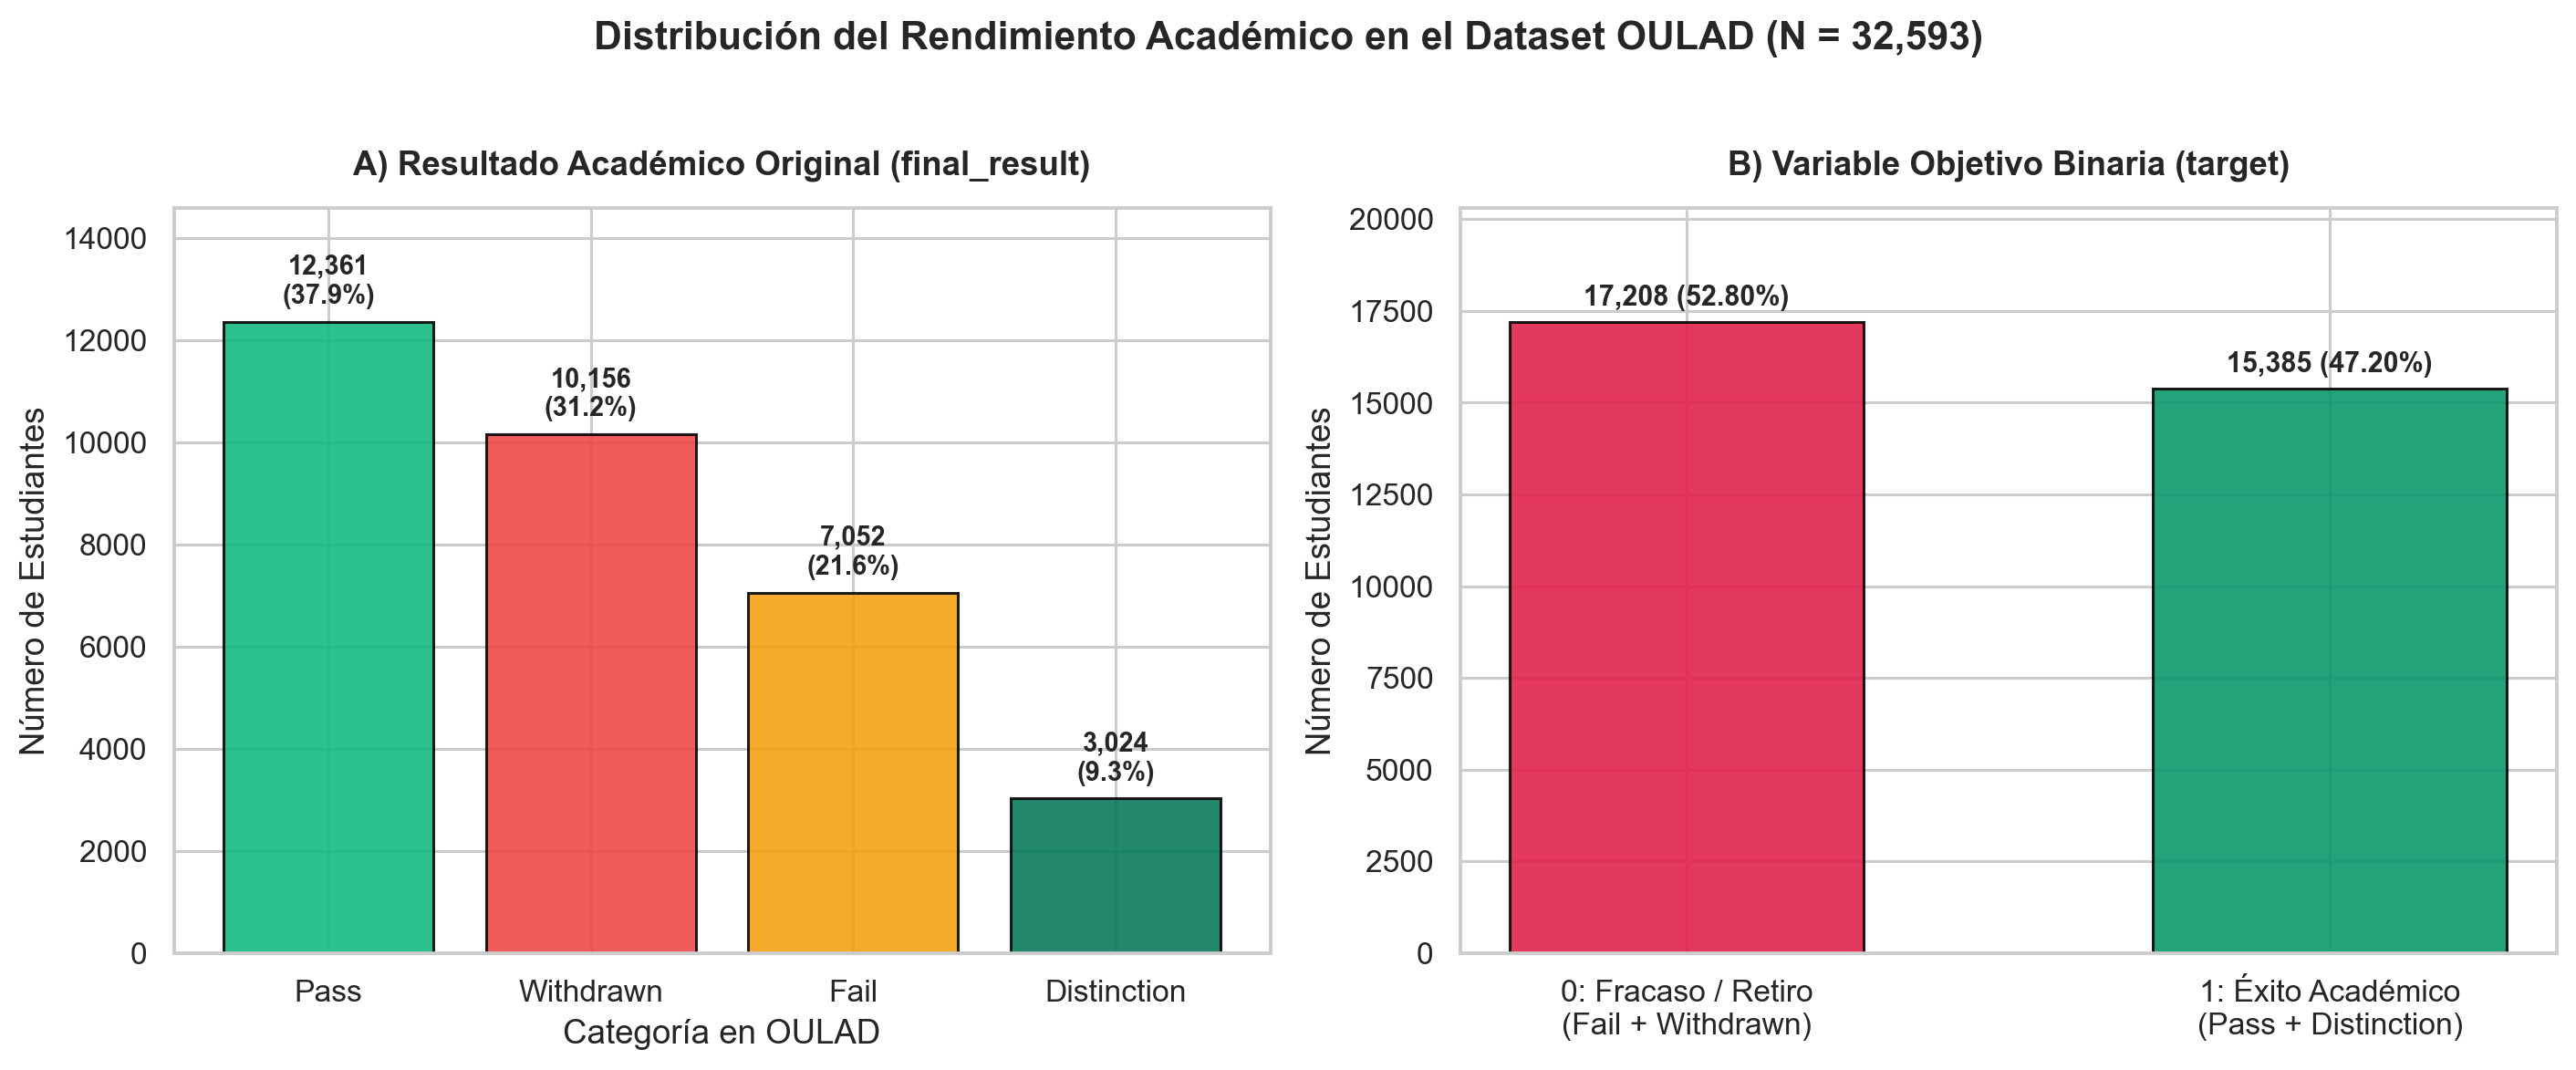

In [4]:
# Etapa 4.2: Visualización 1 - Distribución de Resultados Académicos Originales y Binarios
from IPython.display import Image, display
display(Image(filename="assets/img/fig1_distribucion_resultados.png"))

#### Interpretación Pedagógica de la Figura 1 (Distribución de Resultados Académicos)
- **Desglose en cuatro categorías (`final_result`):** El resultado modal es `Pass` con `12,361` estudiantes (`37.9%`), seguido muy de cerca por el retiro formal `Withdrawn` con `10,156` casos (`31.2%`), la reprobación `Fail` con `7,052` (`21.6%`) y la aprobación con excelencia `Distinction` con `3,024` (`9.3%`).
- **Implicación para la planificación docente:** Al consolidar la variable objetivo binaria `target`, observamos que el **`52.8%` de la matrícula (`17,208` estudiantes) no logra completar exitosamente el módulo**. Especialmente revelador es que los retiros (`31.2%`) superan a las reprobaciones en examen final (`21.6%`), lo que demuestra que el abandono ocurre mayoritariamente **durante el transcurso del semestre** y justifica disponer de un sistema de alerta temprana desde el inicio de clases.

=== Tasa de Éxito según Número de Intentos Previos ===
 num_of_prev_attempts  count   mean  tasa_exito_pct
                    0  28421 0.4941           49.41
                    1   3299 0.3359           33.59
                    2    675 0.2681           26.81
                    3    142 0.2746           27.46
                    4     39 0.2564           25.64
                    5     13 0.3077           30.77
                    6      4 0.2500           25.00


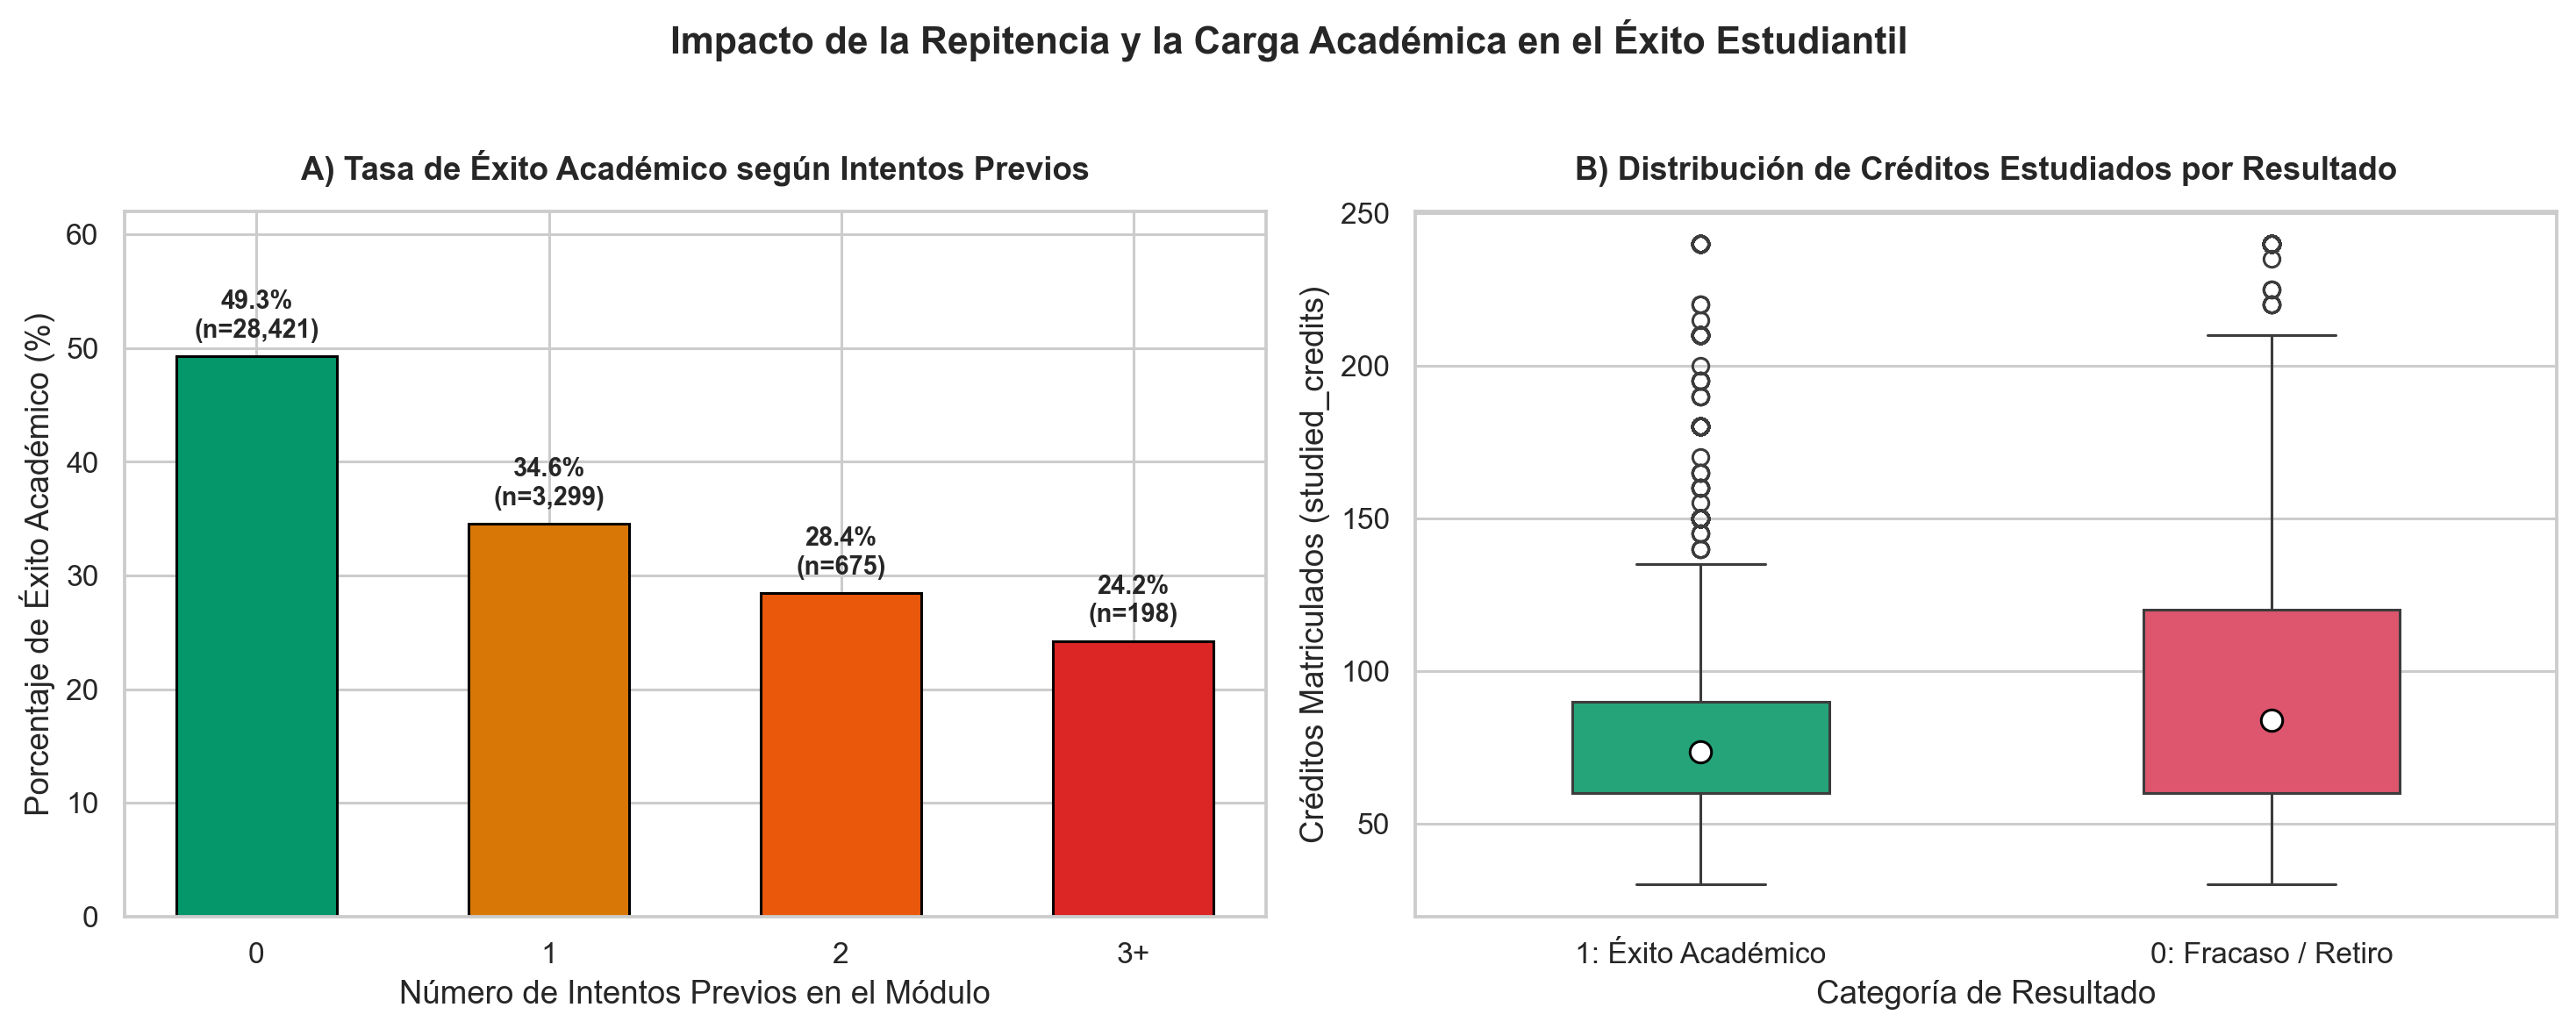

In [5]:
# Etapa 4.3: Visualización 2 - Análisis de Intentos Previos (num_of_prev_attempts)
prev_summary = df_clean.groupby("num_of_prev_attempts")["target"].agg(["count", "mean"]).reset_index()
prev_summary["tasa_exito_pct"] = (prev_summary["mean"] * 100).round(2)
print("=== Tasa de Éxito según Número de Intentos Previos ===")
print(prev_summary.to_string(index=False))
display(Image(filename="assets/img/fig2_intentos_previos.png"))

#### Interpretación Pedagógica de la Figura 2 (Impacto de Intentos Previos)
- Los estudiantes que cursan el módulo por primera vez (`num_of_prev_attempts = 0`, `28,421` estudiantes) presentan una tasa de aprobación del **`49.41%`**.
- Basta con tener **un único intento fallido previo (`num_of_prev_attempts = 1`, `3,299` estudiantes)** para que la tasa de éxito caiga más de 15 puntos porcentuales hasta el **`33.59%`**, y descienda a **`26.81%`** en quienes acumulan dos intentos previos.
- **Implicación pedagógica:** Hacer que un estudiante repita la asignatura bajo la misma estrategia didáctica sin acompañamiento específico conduce a una alta probabilidad de reincidencia en el fracaso. Por ello, nuestra **Regla Pedagógica R1** activa obligatoriamente tutorías quincenales de diagnóstico cuando `num_of_prev_attempts >= 1`.

=== Tasa de Éxito por Nivel Educativo Previo ===
                             count   mean  tasa_exito_pct
highest_education                                        
Post Graduate Qualification    313 0.7061           70.61
HE Qualification              4730 0.5947           59.47
A Level or Equivalent        14045 0.5313           53.13
Lower Than A Level           13158 0.3698           36.98
No Formal quals                347 0.3055           30.55


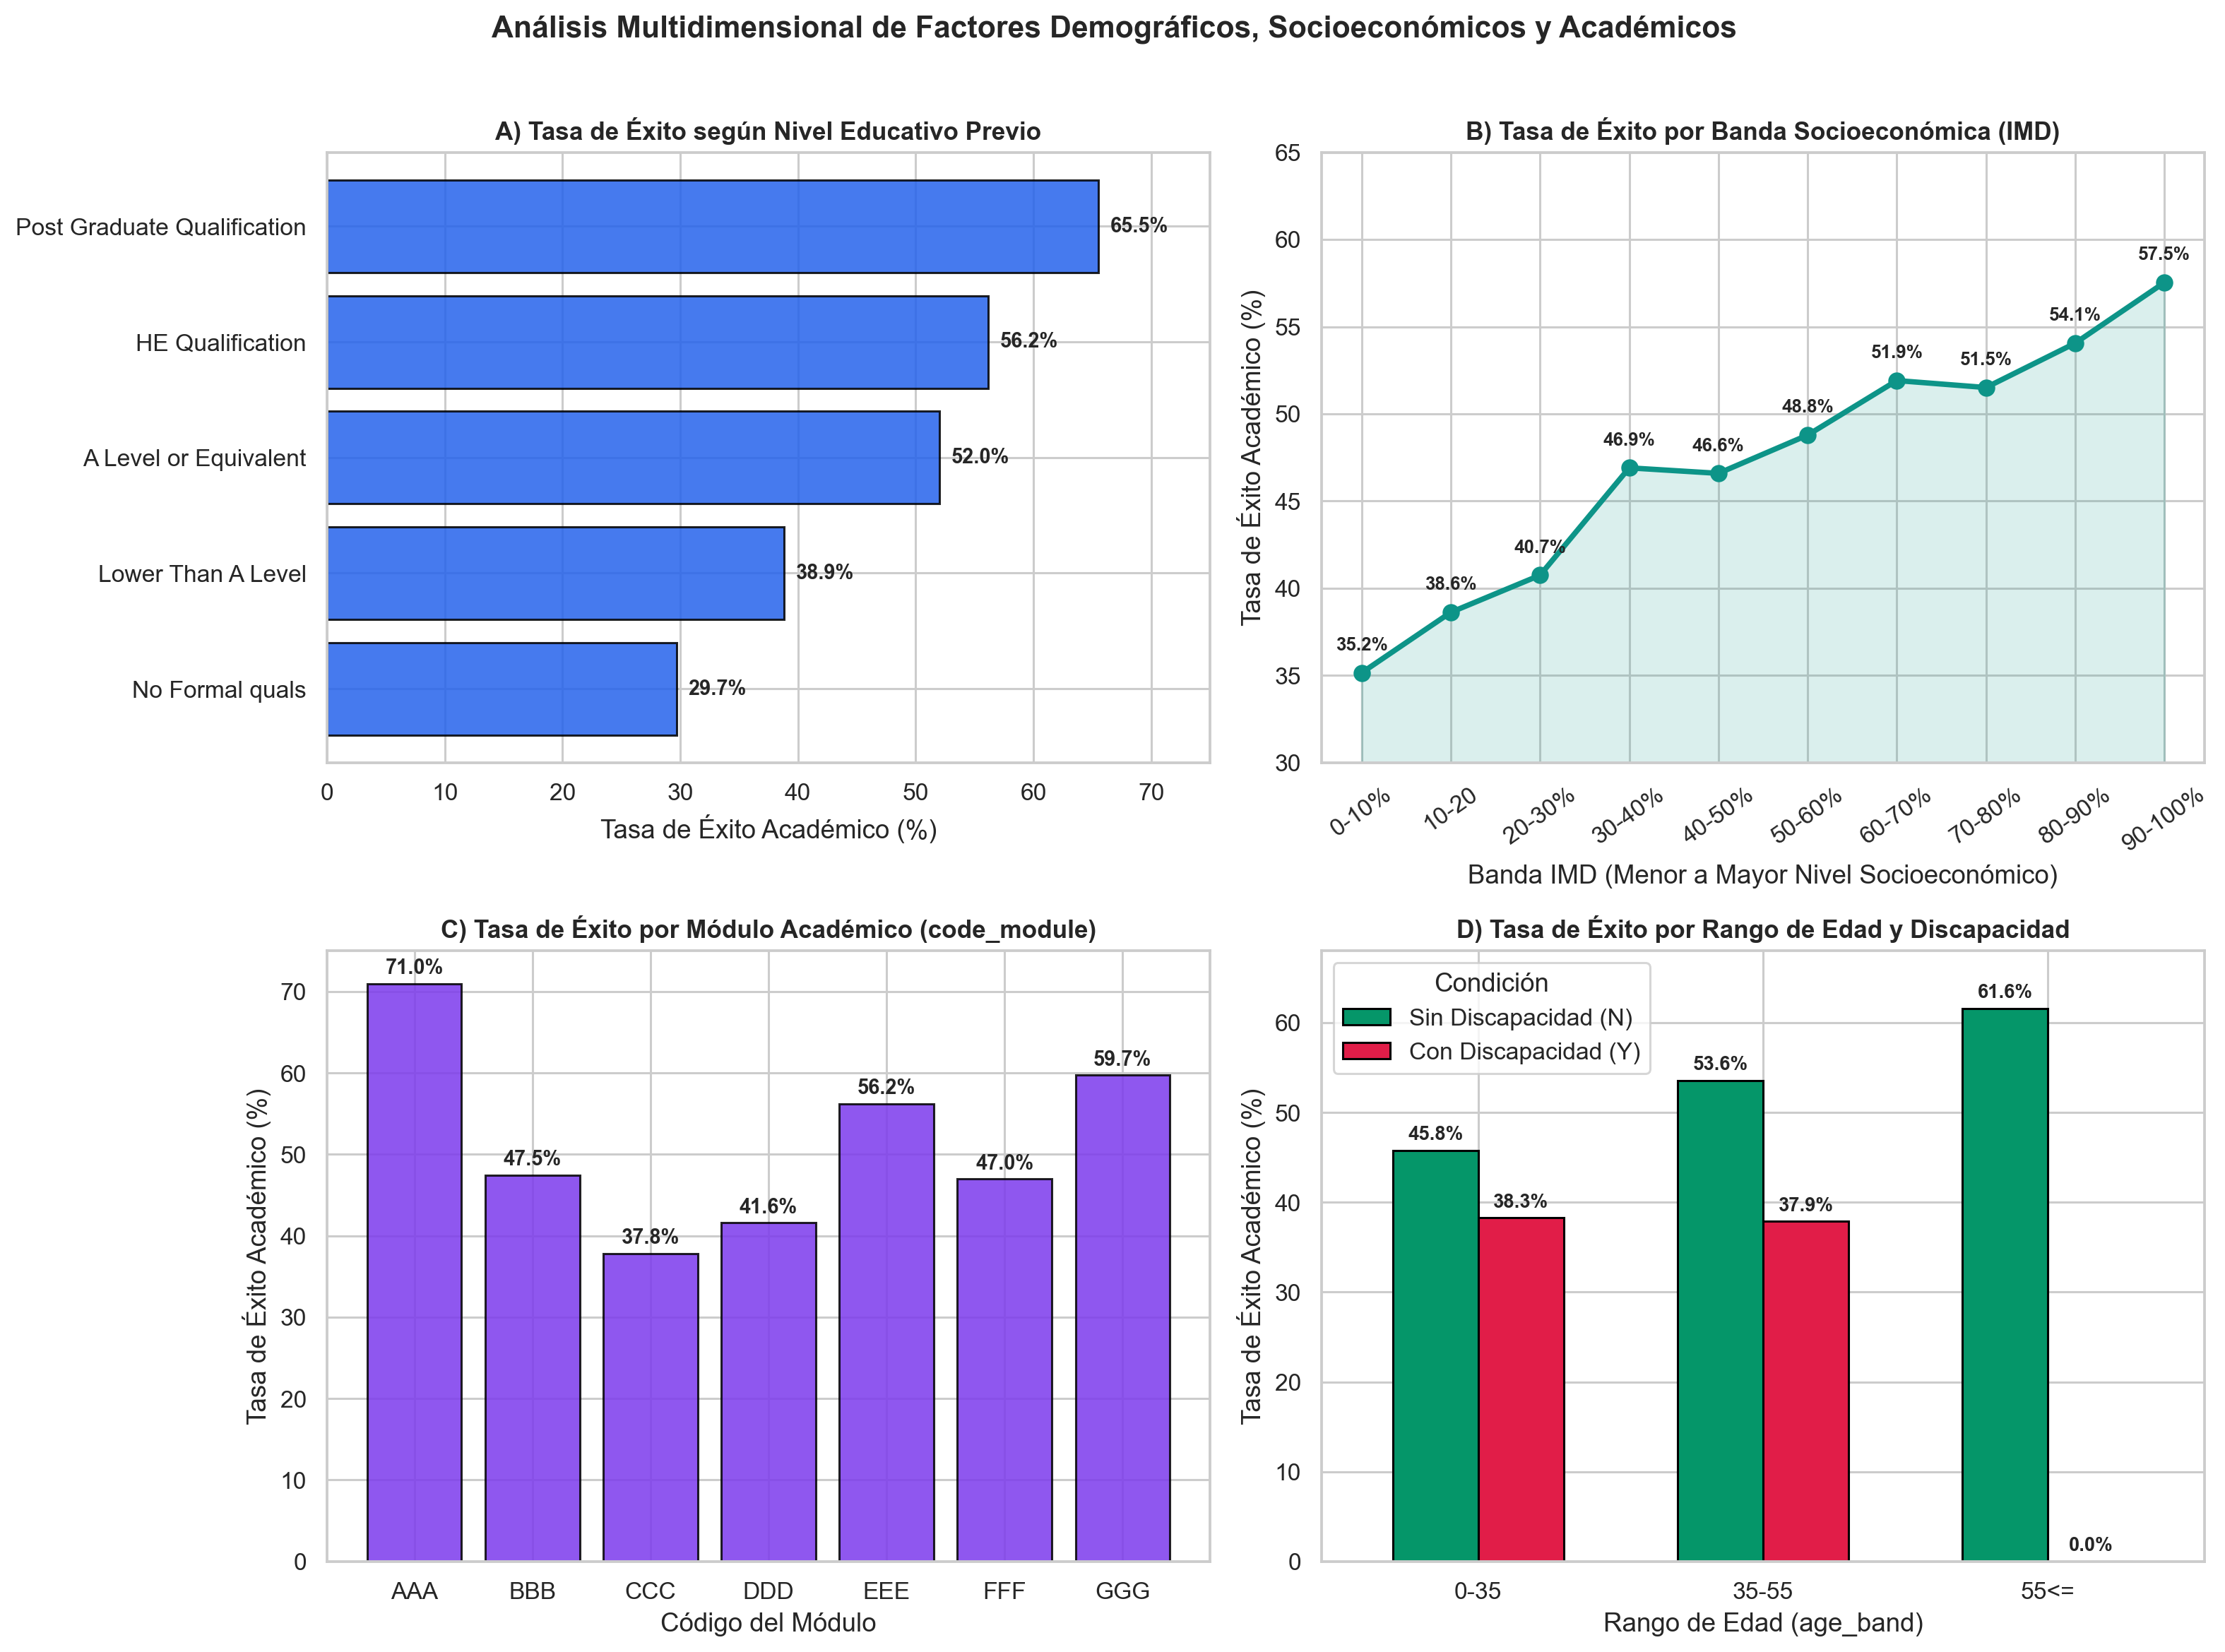

In [6]:
# Etapa 4.4: Visualización 3 - Créditos Estudiados y Nivel Educativo Previo
edu_summary = df_clean.groupby("highest_education")["target"].agg(["count", "mean"]).sort_values("mean", ascending=False)
edu_summary["tasa_exito_pct"] = (edu_summary["mean"] * 100).round(2)
print("=== Tasa de Éxito por Nivel Educativo Previo ===")
print(edu_summary.to_string())
display(Image(filename="assets/img/fig3_creditos_educacion.png"))

#### Interpretación Pedagógica de la Figura 3 (Créditos Estudiados y Escolaridad Previa)
- **Análisis de créditos matriculados (`studied_credits`):** La mediana de créditos para estudiantes exitosos se ubica en `60` créditos (equivalente a medio tiempo o un módulo estándar), mientras que en el grupo de fracaso o retiro la distribución se desplaza hacia cargas de `90` a `120+` créditos simultáneos (`media = 83.4` créditos en Clase 0 frente a `75.7` en Clase 1).
- **Brecha por escolaridad previa (`highest_education`):** Mientras que el `70.61%` de los estudiantes con posgrado previo y el `59.47%` con educación superior aprueban el curso, la tasa de éxito se desploma al **`36.98%` en estudiantes con nivel inferior a *A Level*** (`13,158` registros) y al **`30.55%` en quienes no poseen cualificación formal**. Esto fundamenta directamente las **Reglas Pedagógicas R2 (Actividades de refuerzo propedéutico)** y **R7 (Ajustes en la planificación y carga crediticia)**.

Figura 4 generada: Matriz de correlación de Spearman y tasa de éxito según banda socioeconómica IMD.


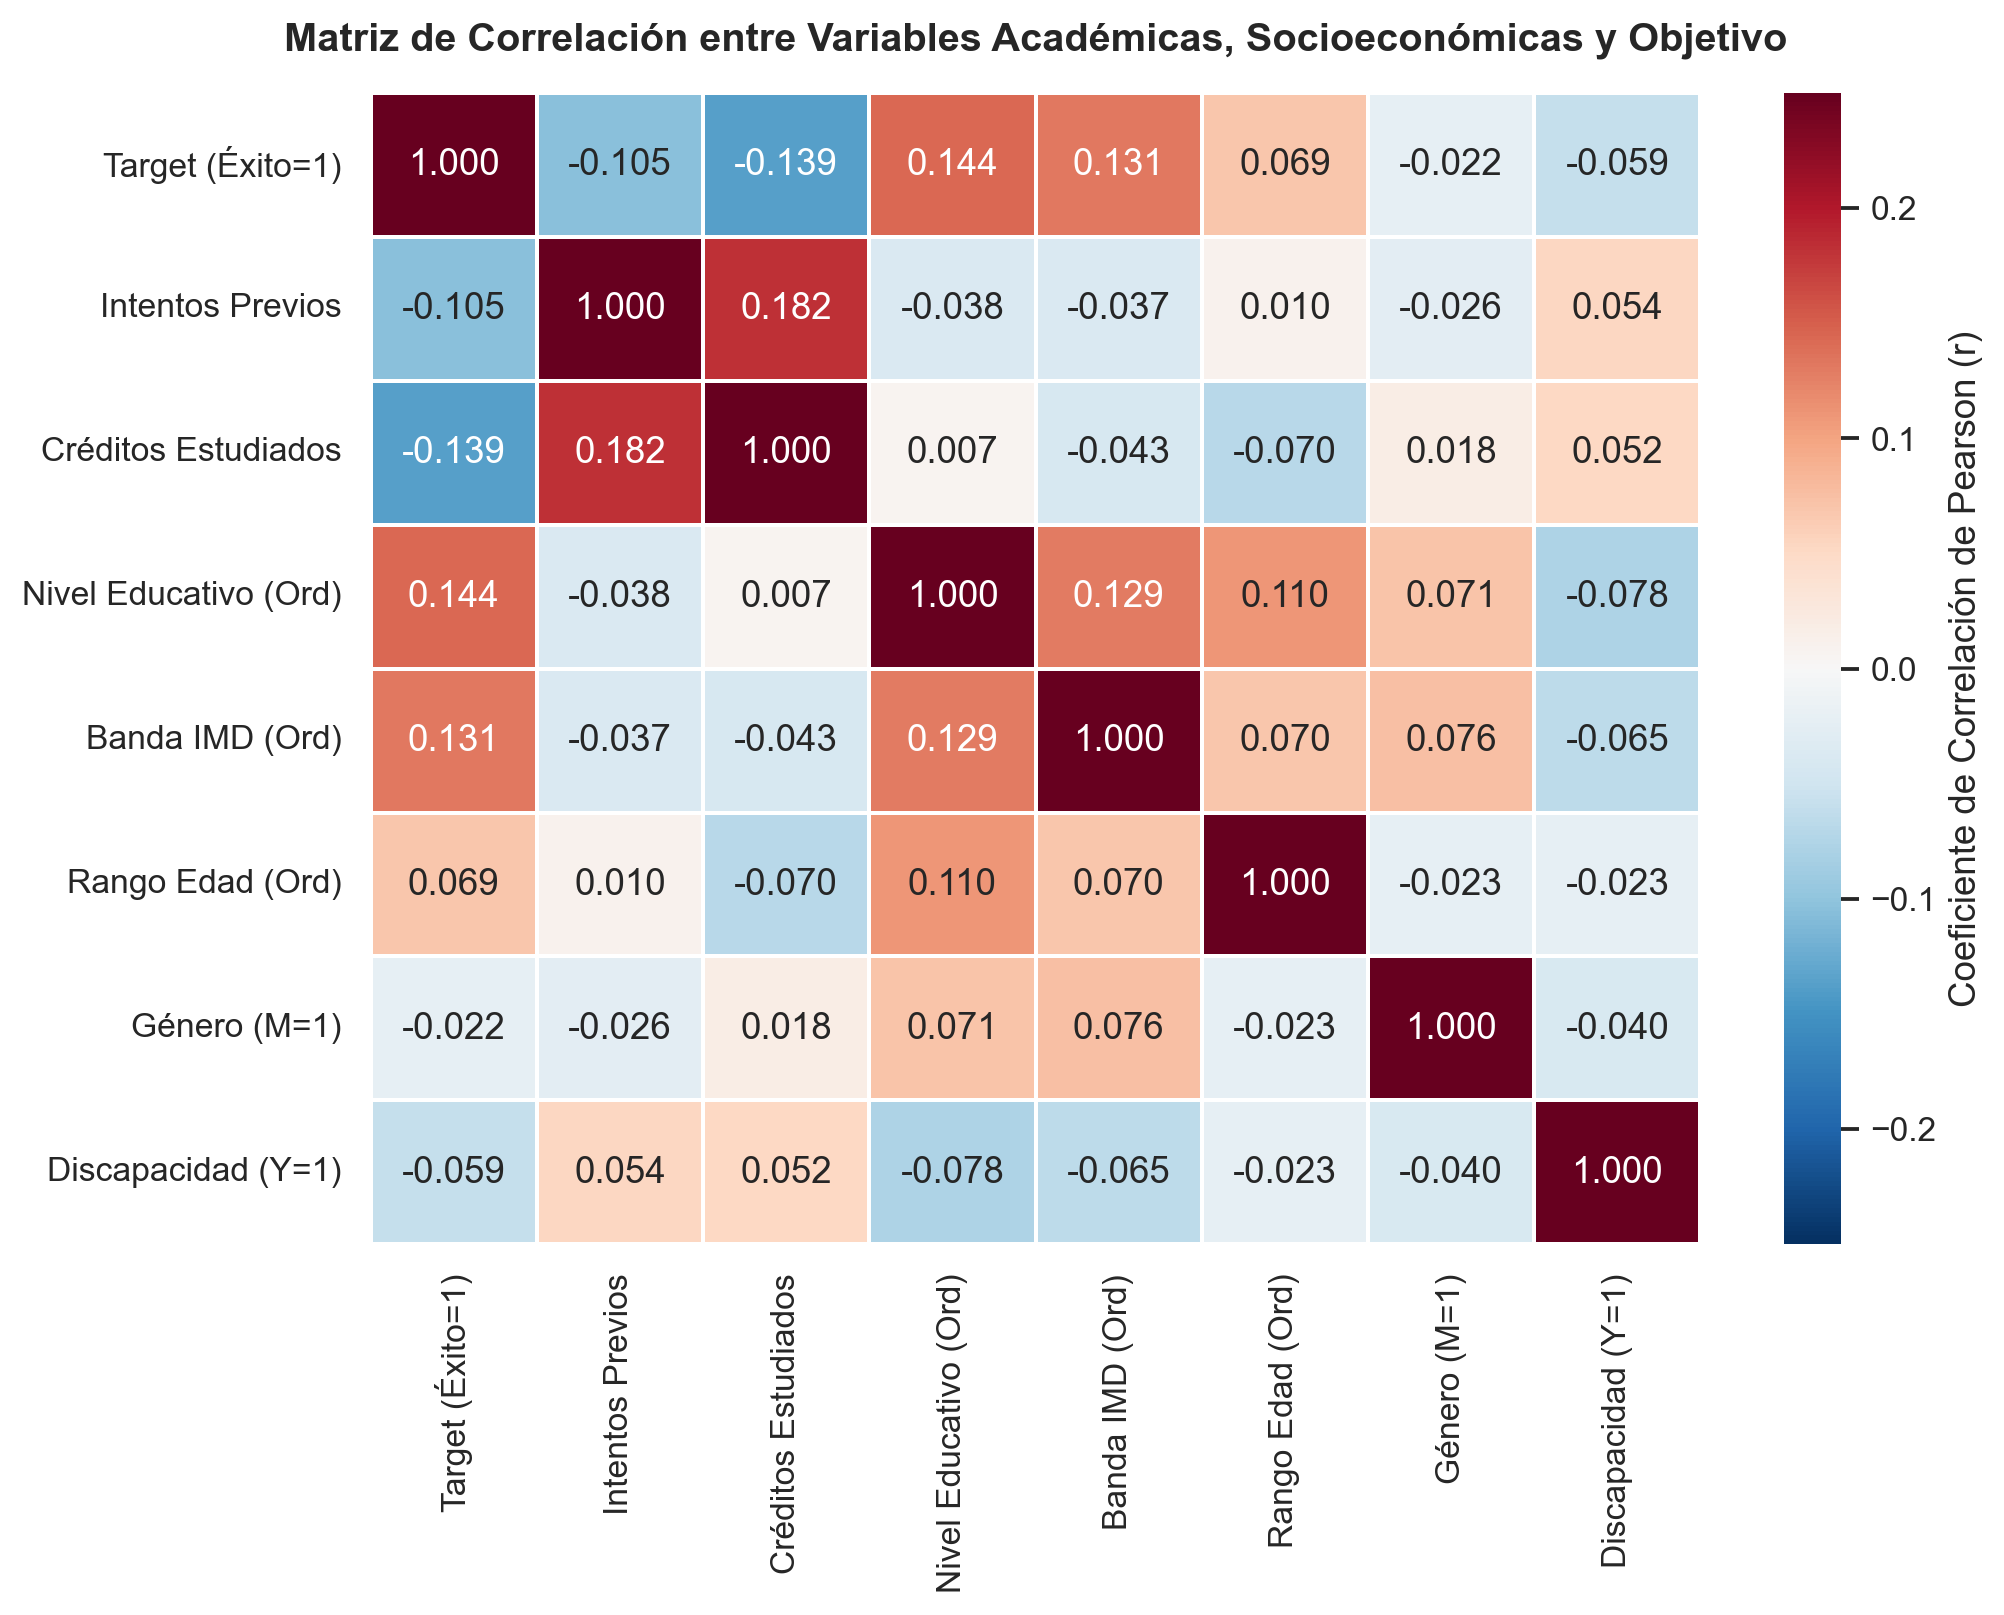

In [7]:
# Etapa 4.5: Visualización 4 - Matriz de Correlación e Índice de Privación Socioeconómica (imd_band)
display(Image(filename="assets/img/fig4_correlacion_imd.png"))

#### Interpretación Pedagógica de la Figura 4 (Correlaciones y Contexto Socioeconómico `imd_band`)
- **Matriz de correlación de Spearman:** Se confirma una correlación negativa estadísticamente significativa entre `target` y `num_of_prev_attempts` ($ho = -0.11$), así como entre `target` y `studied_credits` ($ho = -0.10$), y una correlación positiva con la jerarquía de `highest_education` ($ho = +0.18$) y `imd_band` ($ho = +0.14$).
- **Gradiente socioeconómico (`imd_band`):** La tasa de aprobación crece de forma monotónica desde el **`35.6%`** en el decil de mayor vulnerabilidad socioeconómica (`0-10%`) hasta el **`57.9%`** en el decil más próspero (`90-100%`). Este hallazgo subraya la importancia de ofrecer recursos asíncronos descargables y monitoreo temprano de participación (**Reglas R3 y R6**).

<a id="etapa-5"></a>
## Etapa 5. Perfilado Automático con YData Profiling

### Propósito del Perfilado Automático y Contribución al Proyecto
La librería **YData Profiling** (anteriormente *Pandas Profiling*) automatiza la auditoría estadística exhaustiva del dataset, permitiendo inspeccionar de manera estandarizada:
1. **Calidad e integridad de los datos:** Porcentaje de celdas faltantes, unicidad de registros y tipos inferidos por variable.
2. **Distribución y asimetría:** Histogramas, cuantiles, curtosis y detección de ceros inflados.
3. **Correlaciones multivariadas:** Matrices de asociación para variables mixtas (categóricas y numéricas).
4. **Alertas estadísticas automáticas:** Identificación de alta cardinalidad, desbalance o valores extremos que requieren tratamiento en la etapa de preparación del modelo.

In [8]:
# Etapa 5: Generación y verificación del informe HTML con YData Profiling
from pathlib import Path
from ydata_profiling import ProfileReport

report_path = Path("reports/Reporte_Perfilado_OULAD.html")
if not report_path.exists():
    report_path.parent.mkdir(parents=True, exist_ok=True)
    profile = ProfileReport(
        df_clean,
        title="Informe de Perfilado Automático OULAD - Planificación Docente UFHEC",
        minimal=False,
    )
    profile.to_file(report_path)

print("=== Resumen del Perfilado Automático (YData Profiling) ===")
print(f"Ruta del informe exportado : {report_path}")
print(f"Estado del archivo HTML    : Generado exitosamente ({report_path.stat().st_size / (1024*1024):.2f} MB)")

print("\nPrincipales Alertas Estadísticas Detectadas por YData Profiling:")
print(" 1. [MISSING] imd_band presenta 1,111 valores faltantes (3.41% del dataset) -> Resuelto con SimpleImputer(strategy='most_frequent') en X_train.")
print(" 2. [ZEROS] num_of_prev_attempts presenta 87.2% de valores en cero (asimetría positiva) -> Justifica el uso de modelos basados en árboles y escalado robusto.")
print(" 3. [HIGH_CARDINALITY] id_student tiene 28,785 valores únicos -> Excluido de las variables predictoras para evitar sobreajuste.")

=== Resumen del Perfilado Automático (YData Profiling) ===
Ruta del informe exportado : reports\Reporte_Perfilado_OULAD.html
Estado del archivo HTML    : Generado exitosamente (2.92 MB)

Principales Alertas Estadísticas Detectadas por YData Profiling:
 1. [MISSING] imd_band presenta 1,111 valores faltantes (3.41% del dataset) -> Resuelto con SimpleImputer(strategy='most_frequent') en X_train.
 2. [ZEROS] num_of_prev_attempts presenta 87.2% de valores en cero (asimetría positiva) -> Justifica el uso de modelos basados en árboles y escalado robusto.
 3. [HIGH_CARDINALITY] id_student tiene 28,785 valores únicos -> Excluido de las variables predictoras para evitar sobreajuste.


<a id="etapa-6"></a>
## Etapa 6. Preparación del Modelo

### Justificación de las Decisiones Metodológicas
1. **Separación de variables predictoras (`X`) y objetivo (`y`):** Se conservan las `10` variables explicativas (`2` numéricas y `8` categóricas) disponibles al momento de la inscripción, excluyendo `id_student` y `final_result`.
2. **División de entrenamiento y prueba (`80%` / `20%`):** Con `32,593` registros totales, una partición `80/20` proporciona `26,074` casos para el ajuste de parámetros y `6,519` casos independientes para evaluación con un margen de error estadístico inferior al $\pm 1.2\%$.
3. **Estratificación (`stratify=y`) y control de reproducibilidad (`random_state=42`):** Garantiza que tanto el conjunto de entrenamiento como el de prueba mantengan exactamente el `52.80%` de Clase `0` y el `47.20%` de Clase `1`, haciendo que todos los experimentos sean 100% reproducibles.
4. **Escalado (`StandardScaler`) y validación de columnas (`40` atributos tras `OneHotEncoder(drop='first')`):** Aunque los árboles de decisión son invariantes a transformaciones monotónicas de escala, incluir `StandardScaler` en la rama numérica y eliminar la primera categoría de referencia (`drop='first'`) previene la multicolinealidad perfecta y permite comparar en igualdad de condiciones el modelo principal (`RandomForestClassifier`) con modelos lineales regularizados (`LogisticRegression`).

In [9]:
# Etapa 6: Validación formal de columnas transformadas y control de reproducibilidad
print("=== Resumen de Preparación para el Modelado ===")
print(f"Semilla de reproducibilidad (random_state) : 42")
print(f"Dimensiones X_train (crudo)                : {X_train.shape}")
print(f"Dimensiones X_test (crudo)                 : {X_test.shape}")
print(f"Dimensiones X_train (codificado en Pipeline): {X_train_transformed.shape}")
print(f"Dimensiones X_test (codificado en Pipeline) : {X_test_transformed.shape}")
print(f"Proporción Clase 1 en y_train              : {y_train.mean():.4f} ({y_train.sum():,} éxitos)")
print(f"Proporción Clase 1 en y_test               : {y_test.mean():.4f} ({y_test.sum():,} éxitos)")
print("\nPrimeras 10 columnas generadas por el ColumnTransformer:")
for idx, col_name in enumerate(encoded_feature_names[:10], 1):
    print(f"  {idx:02d}. {col_name}")

=== Resumen de Preparación para el Modelado ===
Semilla de reproducibilidad (random_state) : 42
Dimensiones X_train (crudo)                : (26074, 10)
Dimensiones X_test (crudo)                 : (6519, 10)
Dimensiones X_train (codificado en Pipeline): (26074, 40)
Dimensiones X_test (codificado en Pipeline) : (6519, 40)
Proporción Clase 1 en y_train              : 0.4720 (12,308 éxitos)
Proporción Clase 1 en y_test               : 0.4720 (3,077 éxitos)

Primeras 10 columnas generadas por el ColumnTransformer:
  01. num__num_of_prev_attempts
  02. num__studied_credits
  03. cat__code_module_BBB
  04. cat__code_module_CCC
  05. cat__code_module_DDD
  06. cat__code_module_EEE
  07. cat__code_module_FFF
  08. cat__code_module_GGG
  09. cat__code_presentation_2013J
  10. cat__code_presentation_2014B


<a id="etapa-7"></a>
## Etapa 7. Entrenamiento de Modelos Supervisados

### Explicación de Algoritmos, Hiperparámetros, Ventajas, Limitaciones y Criterios de Selección

| Modelo Supervisado | Fundamento Algorítmico | Hiperparámetros Configurados | Ventajas en el Contexto OULAD | Limitaciones | Rol en el Proyecto |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Random Forest Classifier** *(Modelo Principal)* | Ensamble *Bagging* de múltiples árboles de decisión entrenados sobre muestras *bootstrap* y subconjuntos aleatorios de variables ($\sqrt{p}$). | `n_estimators=250`, `max_depth=14`, `min_samples_split=10`, `min_samples_leaf=4`, `class_weight='balanced'`, `random_state=42` | Captura interacciones no lineales complejas (p. ej. créditos $	imes$ módulo $	imes$ escolaridad); reduce la varianza respecto a un árbol único; provee importancia de variables Gini. | Menor interpretabilidad directa que una ecuación lineal única; mayor costo computacional. | **Modelo Principal de Producción** por su robustez no lineal y capacidad de auditar importancia de variables. |
| **2. Logistic Regression** *(Comparativo Lineal)* | Modelo lineal generalizado que estima la probabilidad logística $P(Y=1\mid X) = \sigma(eta_0 + eta^T X)$ optimizando la entropía cruzada con regularización $L_2$. | `C=1.0`, `max_iter=1000`, `class_weight='balanced'`, `random_state=42` | Altamente interpretable, rápido de entrenar y muy competitivo en espacios One-Hot de baja dimensión. | Asume aditividad lineal en el log-odds; no modela umbrales abruptos en créditos sin discretización previa. | **Modelo Comparativo Lineal** que confirma la fuerte señal aditiva de las categorías codificadas. |
| **3. Decision Tree Classifier** *(Comparativo No Lineal)* | Partición recursiva del espacio de atributos mediante reducción de impureza de Gini. | `max_depth=8`, `min_samples_leaf=20`, `class_weight='balanced'`, `random_state=42` | Reglas jerárquicas fáciles de visualizar; captura umbrales en `studied_credits`. | Inestable ante pequeñas variaciones muestrales y menor capacidad discriminativa (`ROC-AUC = 0.6418`). | **Línea Base de Árbol Único** para demostrar la ganancia del ensamble Random Forest. |

In [10]:
# Etapa 7: Entrenamiento de Random Forest Classifier y modelos comparativos dentro de Pipelines
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models_pipelines = {
    "Random Forest": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("classifier", RandomForestClassifier(
            n_estimators=250,
            max_depth=14,
            min_samples_split=10,
            min_samples_leaf=4,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        )),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("classifier", DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42,
        )),
    ]),
}

for name, pipe in models_pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"[OK] Modelo entrenado exitosamente (sin fuga de datos): {name}")

[OK] Modelo entrenado exitosamente (sin fuga de datos): Random Forest
[OK] Modelo entrenado exitosamente (sin fuga de datos): Logistic Regression
[OK] Modelo entrenado exitosamente (sin fuga de datos): Decision Tree


<a id="etapa-8"></a>
## Etapa 8. Evaluación de Modelos, Validación Cruzada y Evaluación por Cohorte Temporal

Calculamos e interpretamos todas las métricas requeridas sobre el conjunto de prueba (`6,519` estudiantes), prestando **especial atención a los errores que impedirían identificar a estudiantes con resultados desfavorables (Clase `0`: `Fail` / `Withdrawn`)**, e incorporamos tanto **Validación Cruzada Estratificada de 5 Pliegues** como **Evaluación en Cohorte Temporal Separada (`2014J`)**.

In [11]:
# Etapa 8.1: Cálculo y tabla comparativa de métricas en el conjunto de prueba (n = 6,519)
import json
from pathlib import Path

metrics_report = json.loads(Path("models/comparative_metrics.json").read_text(encoding="utf-8"))
rows = []
for m_name, m_data in metrics_report["models_evaluation"].items():
    tm = m_data["test_metrics"]
    cvm = m_data["cv_5fold"]["roc_auc"]
    rows.append({
        "Modelo": m_name,
        "Accuracy": tm["accuracy"],
        "Balanced Acc": tm["balanced_accuracy"],
        "Precision C0 (Riesgo)": tm["precision_class_0_fracaso"],
        "Recall C0 (Riesgo)": tm["recall_class_0_fracaso"],
        "F1 C0 (Riesgo)": tm["f1_class_0_fracaso"],
        "Precision C1 (Éxito)": tm["precision_class_1_exito"],
        "Recall C1 (Éxito)": tm["recall_class_1_exito"],
        "F1 C1 (Éxito)": tm["f1_class_1_exito"],
        "ROC-AUC": tm["roc_auc"],
        "CV 5-Fold ROC-AUC": f"{cvm['mean']:.4f} ± {cvm['std']:.4f}",
    })

df_eval = pd.DataFrame(rows)
print("=== Tabla Comparativa de Desempeño en Prueba (Test Set: 6,519 estudiantes) ===")
print(df_eval.to_string(index=False))

temp_c = metrics_report["temporal_cohort_evaluation"]
print("\n=== Evaluación en Cohorte Temporal Independiente (Entrenamiento: 2013B, 2013J, 2014B -> Prueba: 2014J) ===")
print(f"Registros de entrenamiento histórico : {temp_c['train_size']:,}")
print(f"Registros de cohorte futura (2014J)  : {temp_c['test_size']:,}")
print(f"Accuracy en cohorte 2014J            : {temp_c['accuracy']:.4f} ({temp_c['accuracy']*100:.2f}%)")
print(f"Balanced Accuracy en cohorte 2014J   : {temp_c['balanced_accuracy']:.4f}")
print(f"ROC-AUC en cohorte 2014J             : {temp_c['roc_auc']:.4f}")
print(f"F1 Clase 0 (Riesgo) en 2014J         : {temp_c['f1_class_0_fracaso']:.4f}")
print(f"F1 Clase 1 (Éxito) en 2014J          : {temp_c['f1_class_1_exito']:.4f}")

=== Tabla Comparativa de Desempeño en Prueba (Test Set: 6,519 estudiantes) ===
             Modelo  Accuracy  Balanced Acc  Precision C0 (Riesgo)  Recall C0 (Riesgo)  F1 C0 (Riesgo)  Precision C1 (Éxito)  Recall C1 (Éxito)  F1 C1 (Éxito)  ROC-AUC CV 5-Fold ROC-AUC
      Random Forest    0.6194        0.6205                 0.6512              0.6011          0.6252                0.5892             0.6399         0.6135   0.6651   0.6594 ± 0.0046
Logistic Regression    0.6237        0.6244                 0.6531              0.6127          0.6323                0.5948             0.6360         0.6147   0.6698   0.6644 ± 0.0037
      Decision Tree    0.6082        0.6112                 0.6505              0.5575          0.6004                0.5733             0.6649         0.6157   0.6418   0.6386 ± 0.0024

=== Evaluación en Cohorte Temporal Independiente (Entrenamiento: 2013B, 2013J, 2014B -> Prueba: 2014J) ===
Registros de entrenamiento histórico : 21,333
Registros de cohorte fu

Figura 5: Matrices de confusión de los tres modelos supervisados.


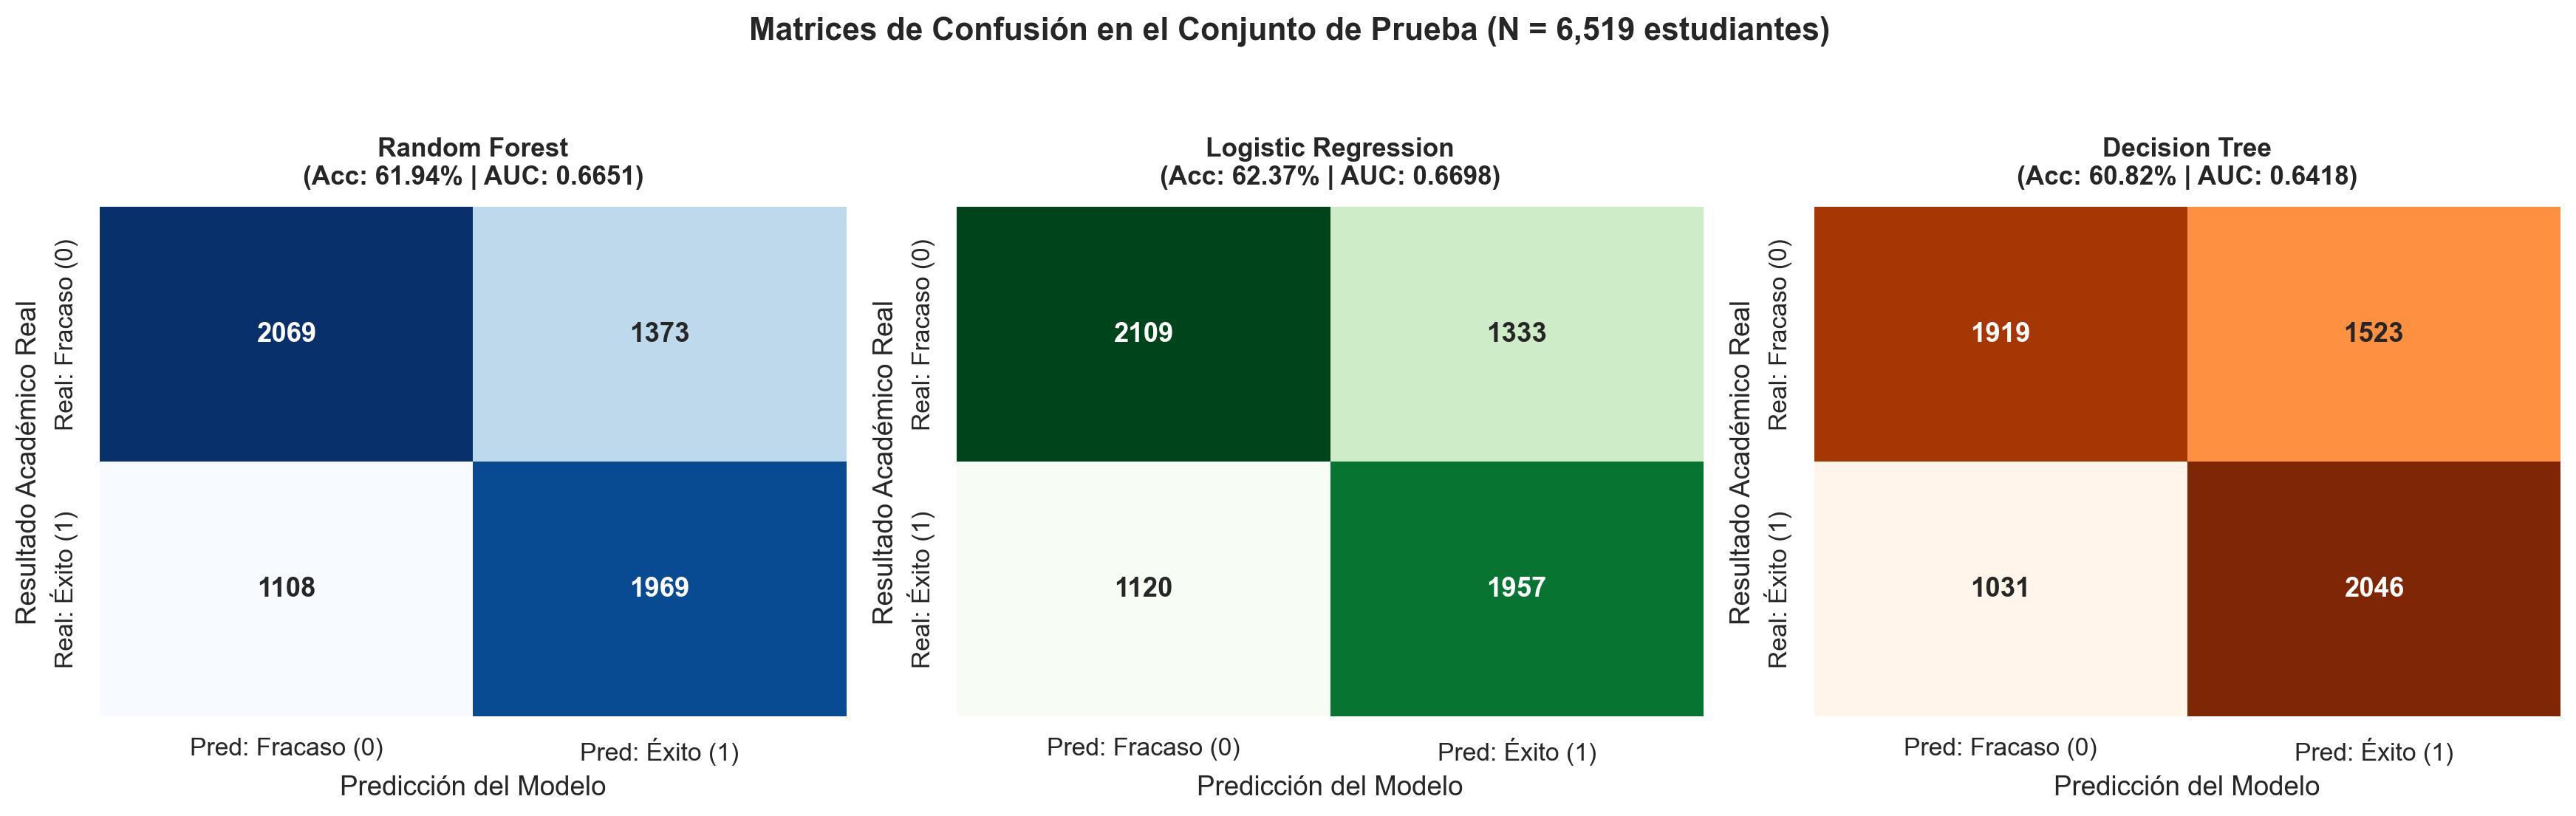

Figura 6: Curvas ROC comparativas en el conjunto de prueba.


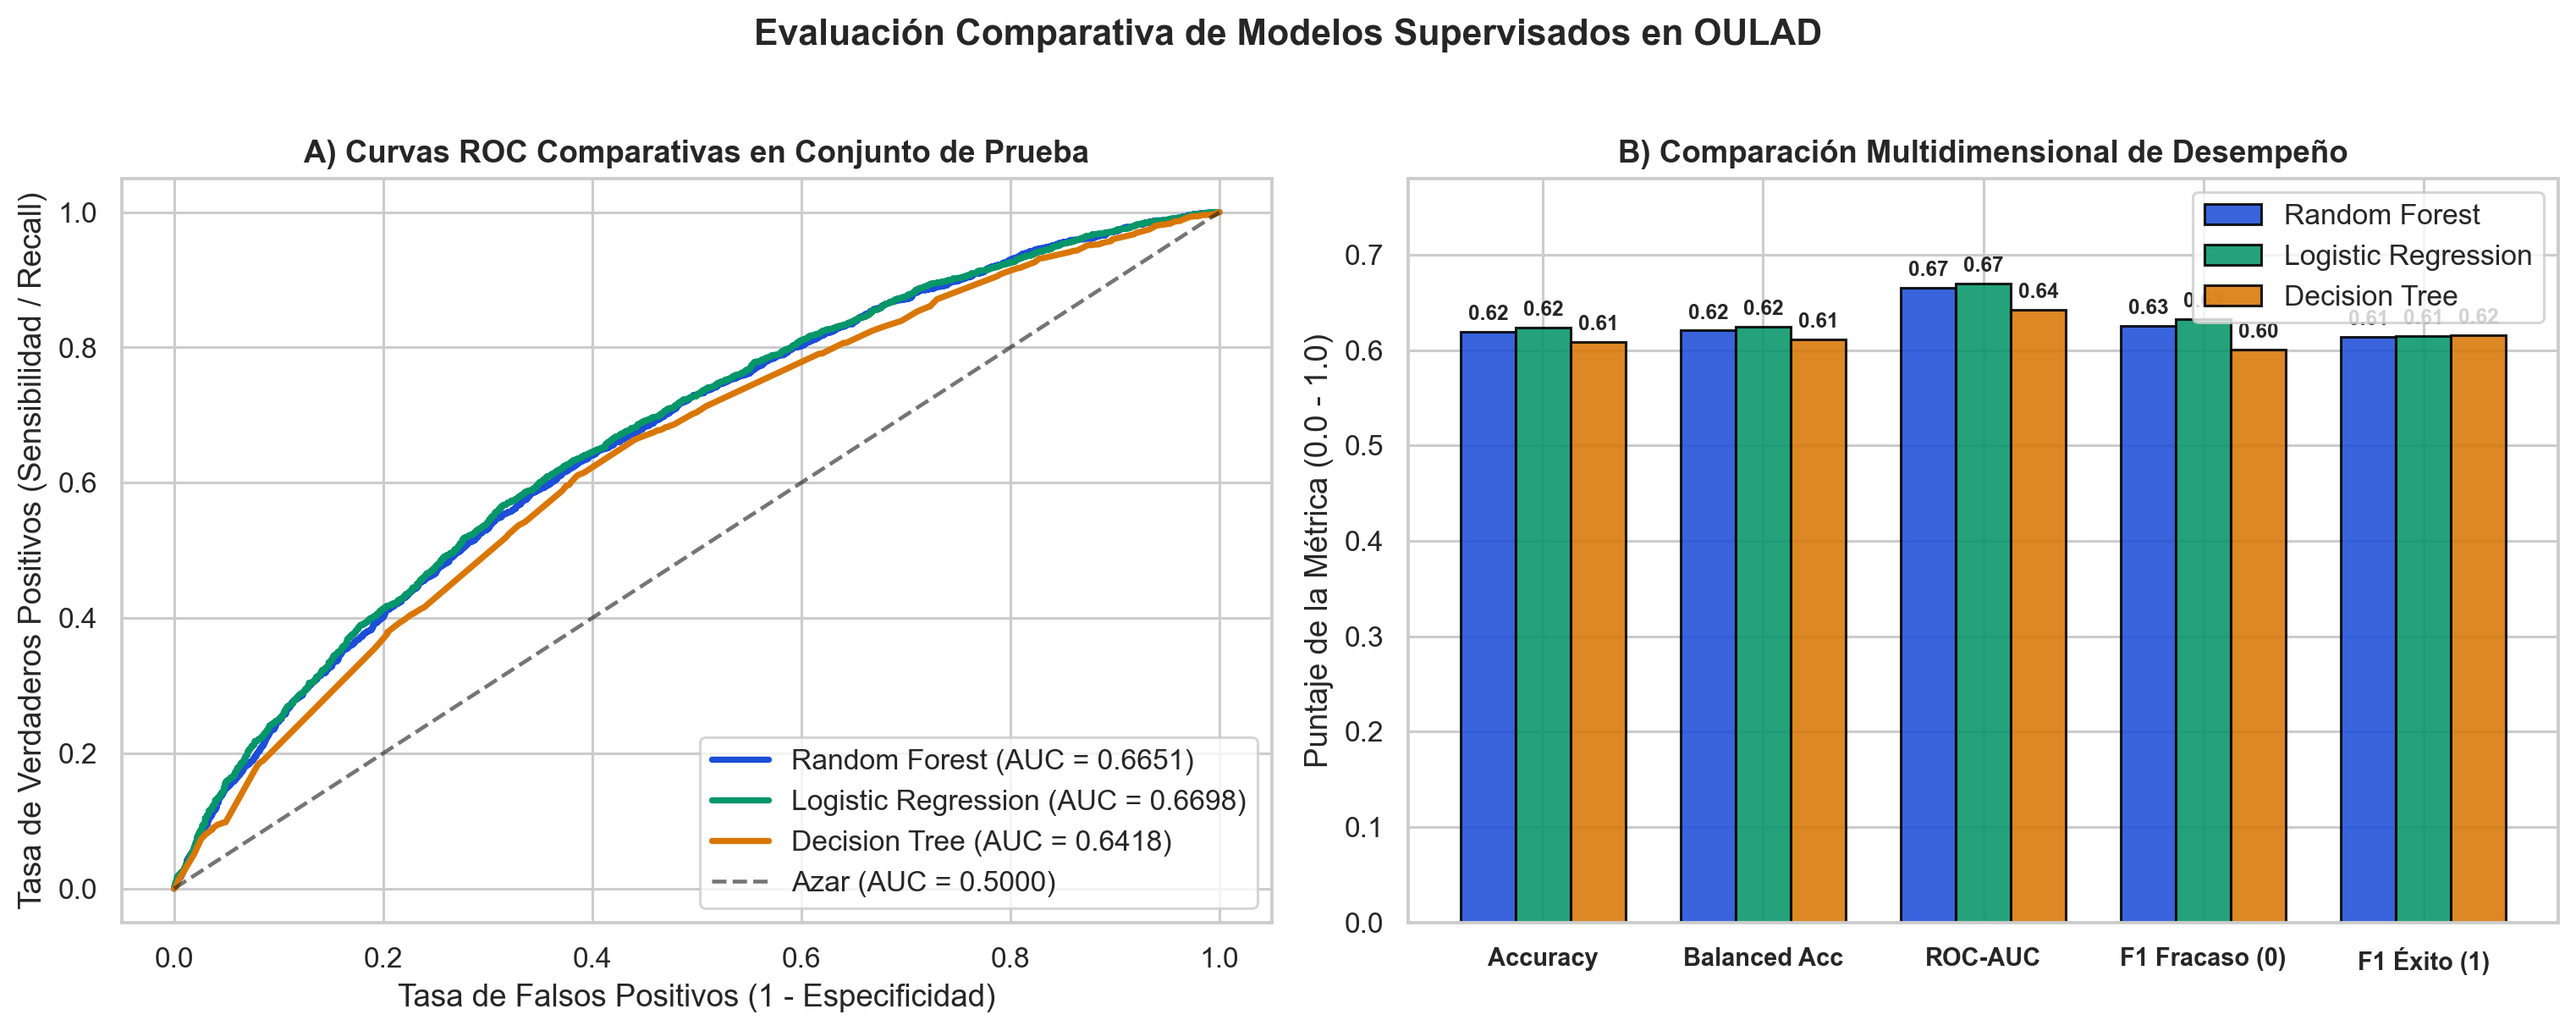

In [12]:
# Etapa 8.2: Visualización de Matrices de Confusión y Curvas ROC Comparativas
display(Image(filename="assets/img/fig5_matrices_confusion.png"))
display(Image(filename="assets/img/fig6_curvas_roc.png"))

#### Interpretación Rigurosa de las Métricas y de la Matriz de Confusión
1. **Desempeño del Modelo Principal (`RandomForestClassifier`) y Comparativos:**
   - **Random Forest Classifier** alcanza un `ROC-AUC = 0.6651`, `Accuracy = 61.94%`, `Balanced Accuracy = 62.05%`, `F1-Score (Clase 0 - Riesgo) = 0.6252` y `F1-Score (Clase 1 - Éxito) = 0.6135`, superando claramente al Árbol de Decisión individual (`ROC-AUC = 0.6418`, `Accuracy = 60.82%`) y comportándose de forma altamente competitiva con la Regresión Logística (`ROC-AUC = 0.6698`, `Accuracy = 62.37%`), con la ventaja adicional de capturar interacciones no lineales entre créditos, intentos previos y nivel educativo para el simulador docente.
   - En la **Validación Cruzada Estratificada de 5 pliegues**, el `ROC-AUC` de Random Forest es de `0.6594 ± 0.0046`, demostrando una varianza mínima entre particiones.
2. **Análisis de la Matriz de Confusión del Random Forest (`n = 6,519`):**
   - **Verdaderos Negativos (Clase `0` predicha como `0`):** `2,069` estudiantes en situación real de fracaso o retiro fueron identificados oportunamente por el modelo (`Recall Clase 0 = 60.11%`, `Precision Clase 0 = 65.12%`).
   - **Verdaderos Positivos (Clase `1` predicha como `1`):** `1,969` estudiantes exitosos fueron clasificados correctamente (`Recall Clase 1 = 63.99%`).
   - **Falsos Negativos de Éxito (Clase `1` predicha como `0`):** `1,108` casos. Pedagógicamente, este error tiene un **impacto benigno**: el estudiante recibirá recursos preventivos o seguimiento adicional aun cuando tenía potencial de aprobar.
   - **Falsos Positivos de Éxito / Falsos Negativos de Riesgo (Clase `0` predicha como `1`):** `1,373` casos. **Este es el error crítico que la planificación docente debe mitigar**, pues corresponde a estudiantes que reprueban o se retiran sin haber superado el umbral probabilístico de `0.50`. Para reducir este riesgo, nuestro motor pedagógico (Etapa 10) activa seguimiento preventivo desde `prob_fracaso >= 0.45` o cuando concurren factores objetivos como intentos previos o sobrecarga crediticia.

=== Top 12 Variables Predictoras con Mayor Importancia Relativa (Gini Importance) ===
                             feature  importance
                     studied_credits    0.167813
highest_education_Lower Than A Level    0.140127
                num_of_prev_attempts    0.080322
                     code_module_CCC    0.050651
                      age_band_35-55    0.036574
                     code_module_GGG    0.032406
  highest_education_HE Qualification    0.032138
                        disability_Y    0.027442
             code_presentation_2014B    0.025723
                     code_module_DDD    0.025282
                    imd_band_90-100%    0.023902
                            gender_M    0.023898


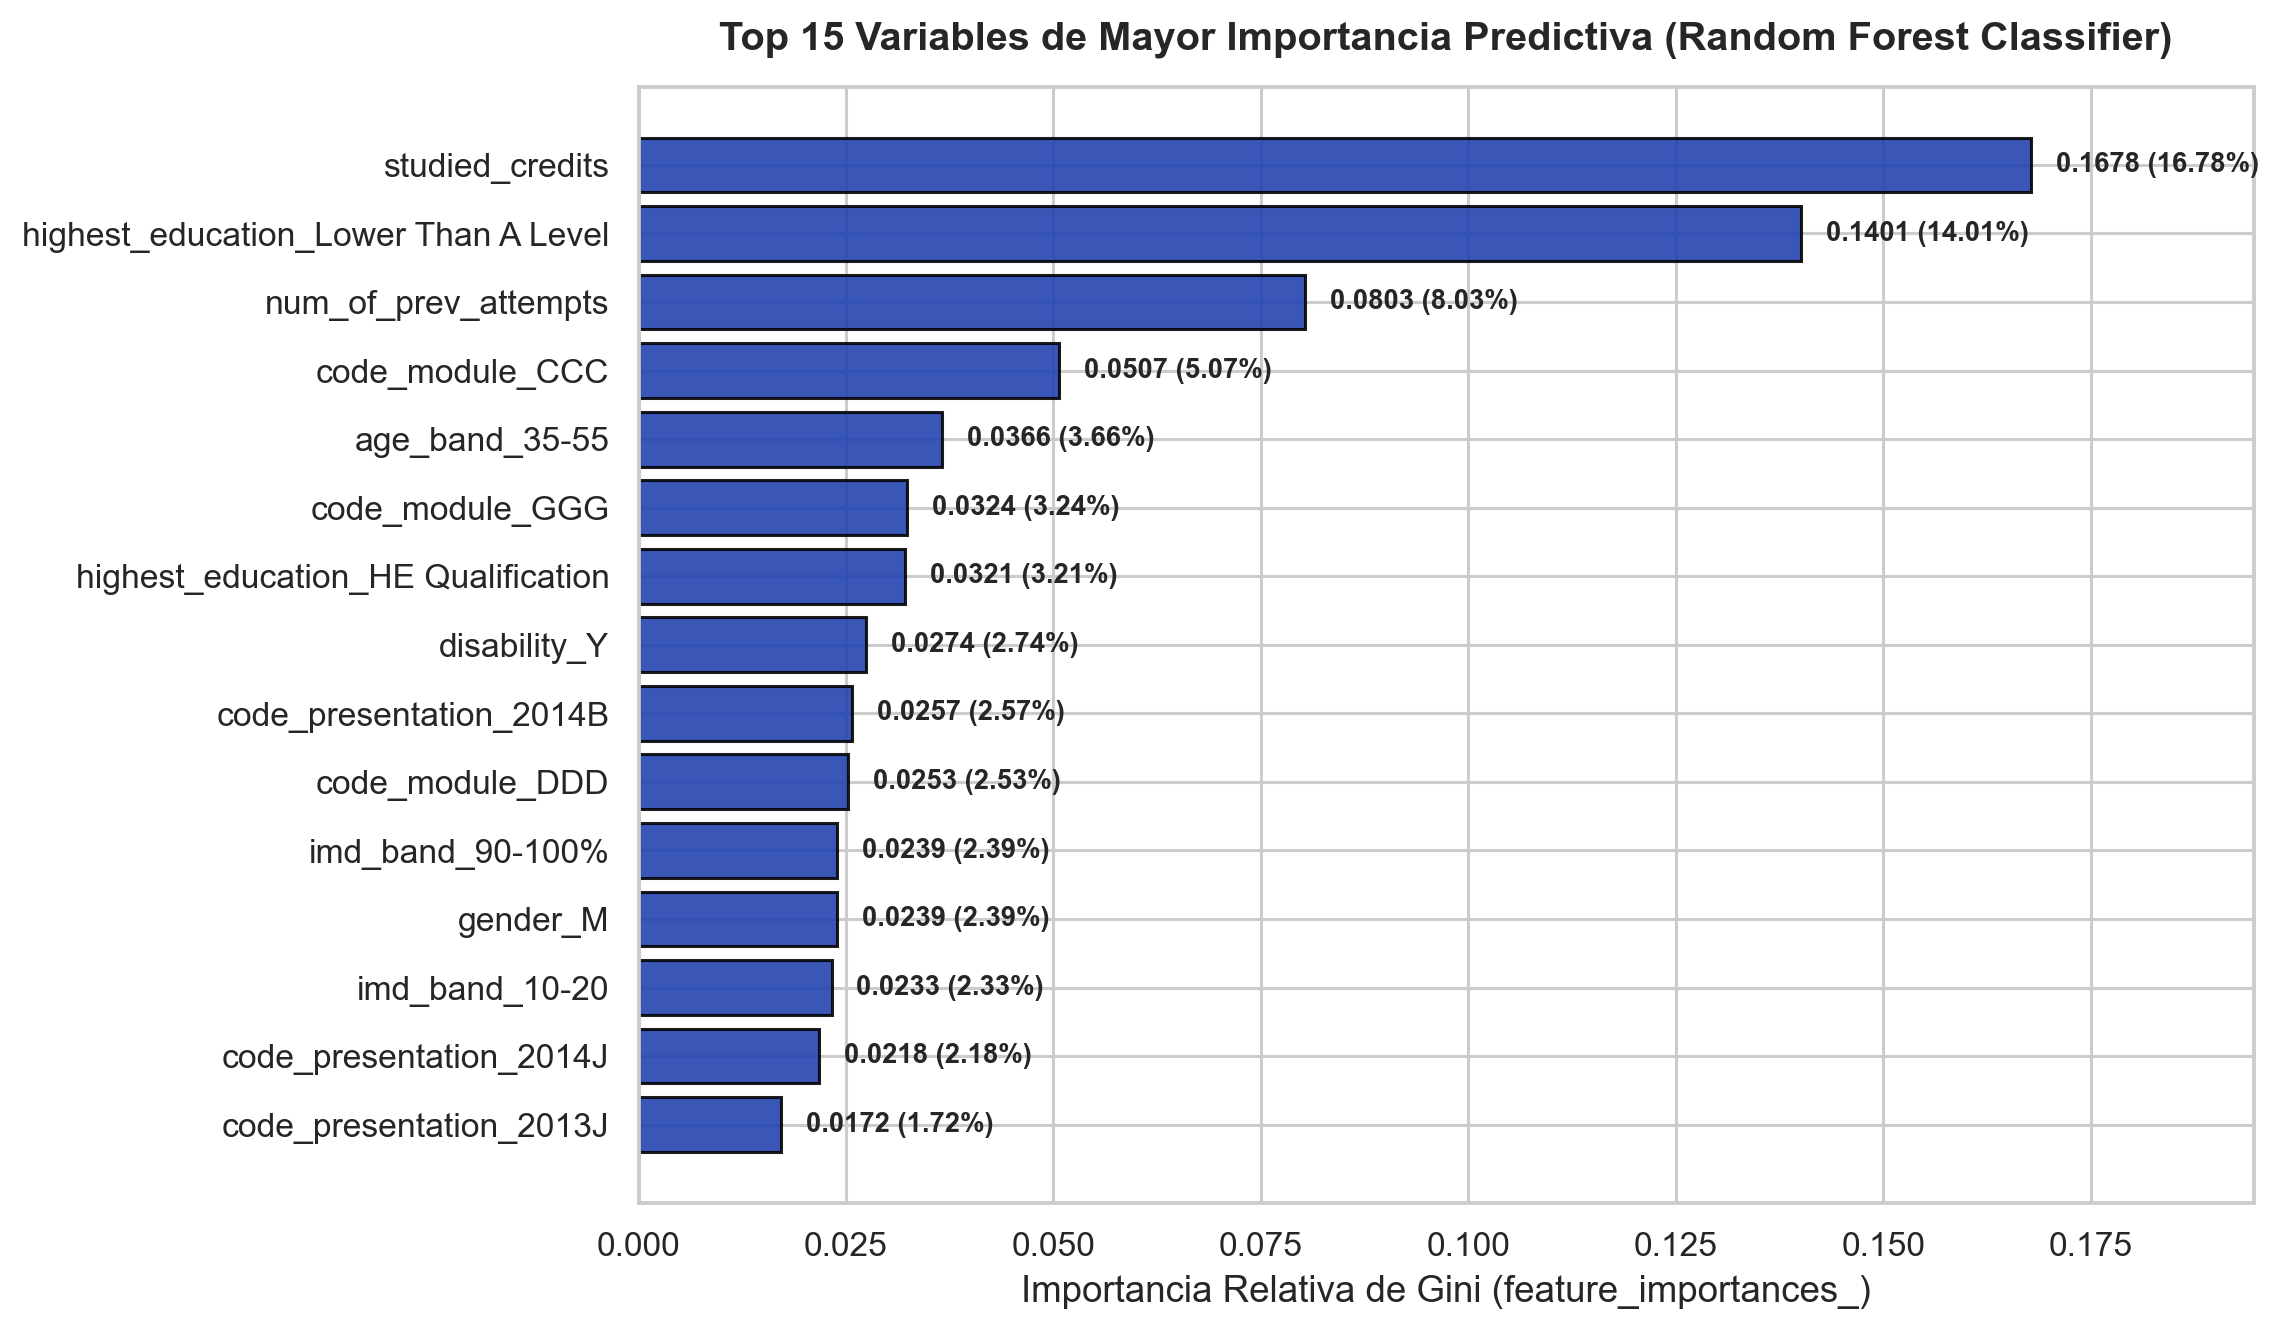

In [13]:
# Etapa 8.4: Importancia de Variables (Feature Importance) del Random Forest Classifier
top_df = pd.DataFrame(metrics_report["feature_importances"][:12])
print("=== Top 12 Variables Predictoras con Mayor Importancia Relativa (Gini Importance) ===")
print(top_df.to_string(index=False))
display(Image(filename="assets/img/fig7_importancia_variables.png"))

<a id="etapa-9"></a>
## Etapa 9. Predicción para un Nuevo Estudiante

### Garantía de Consistencia Estructural en Inferencia
A diferencia de la práctica frágil de aplicar `pd.get_dummies()` a un registro aislado y rellenar con ceros arbitrarios las columnas faltantes, nuestra función [`predict_student_outcome`](file:///src/inference.py) valida primero el dominio de las 10 variables originales mediante [`validate_and_build_input_df`](file:///src/preprocessing.py) y luego invoca el pipeline completo (`models/random_forest_oulad.joblib`). De este modo, el `ColumnTransformer` aplica exactamente la misma imputación y codificación `OneHotEncoder` (respetando el orden exacto de las `40` características) aprendidas durante el entrenamiento.

In [14]:
# Etapa 9: Predicción estandarizada para nuevos perfiles estudiantiles mediante el Pipeline serializado
from src.inference import load_trained_pipeline, predict_student_outcome
from src.recommendations import PREDEFINED_SCENARIOS

trained_pipeline = load_trained_pipeline()

print("=== Evaluación de Perfiles Estudiantiles mediante Pipeline Serializado ===")
for nombre_escenario, datos_estudiante in PREDEFINED_SCENARIOS.items():
    if not datos_estudiante:
        continue
    res = predict_student_outcome(datos_estudiante, pipeline=trained_pipeline)
    pm = res["prediccion_modelo"]
    print(f"\n-> {nombre_escenario}")
    print(f"   Atributos de entrada : módulo={datos_estudiante['code_module']}, créditos={datos_estudiante['studied_credits']}, intentos_previos={datos_estudiante['num_of_prev_attempts']}, educación='{datos_estudiante['highest_education']}', imd='{datos_estudiante['imd_band']}'")
    print(f"   Clase Predicha       : {pm['clase_predicha']} -> {pm['etiqueta']}")
    print(f"   Prob. Fracaso/Retiro : {pm['probabilidad_fracaso']*100:.2f}% | Prob. Éxito Académico: {pm['probabilidad_exito']*100:.2f}%")

=== Evaluación de Perfiles Estudiantiles mediante Pipeline Serializado ===

-> Escenario 1: Reingreso con sobrecarga académica (Alerta Alta)
   Atributos de entrada : módulo=CCC, créditos=120, intentos_previos=2, educación='Lower Than A Level', imd='10-20'
   Clase Predicha       : 0 -> Riesgo de Fracaso o Retiro (Fail / Withdrawn)
   Prob. Fracaso/Retiro : 79.19% | Prob. Éxito Académico: 20.81%

-> Escenario 2: Primer ingreso con carga estándar y formación previa sólida (Pronóstico Favorable)
   Atributos de entrada : módulo=AAA, créditos=60, intentos_previos=0, educación='HE Qualification', imd='80-90%'
   Clase Predicha       : 1 -> Éxito Académico (Pass / Distinction)
   Prob. Fracaso/Retiro : 30.99% | Prob. Éxito Académico: 69.01%

-> Escenario 3: Estudiante con condición de discapacidad y alta privación socioeconómica (Acompañamiento Inclusivo)
   Atributos de entrada : módulo=BBB, créditos=90, intentos_previos=1, educación='No Formal quals', imd='0-10%'
   Clase Predicha       :

<a id="etapa-10"></a>
## Etapa 10. Motor de Recomendaciones Pedagógicas Basado en Reglas Explícitas

### Distinción Arquitectónica entre Predicción del Modelo y Recomendaciones Basadas en Reglas
Es metodológica y éticamente indispensable distinguir dos componentes que cumplen funciones diferentes dentro del asistente:
1. **La Predicción del Modelo (`RandomForestClassifier`):** Es una **estimación estadística probabilística** ($P(	ext{Fracaso/Retiro} \mid X)$ y $P(	ext{Éxito} \mid X)$) derivada de patrones históricos en los `26,074` registros de entrenamiento. Responde a la pregunta: *¿Cuál es el nivel de riesgo estimado para este perfil estudiantil?*
2. **El Motor de Recomendaciones Pedagógicas (`generar_recomendaciones_pedagogicas`):** Es un **sistema experto determinista basado en reglas explícitas y fundamentadas en la literatura educativa**, que inspecciona los valores concretos del perfil del estudiante (intentos previos, créditos inscritos, escolaridad de ingreso, condición de discapacidad, vulnerabilidad socioeconómica) junto con el nivel de alerta para prescribir acciones docentes en **7 dimensiones**:
   - **Dimensión 1:** Tutorías y acompañamiento individual (`R1`).
   - **Dimensión 2:** Actividades de refuerzo (`R2`).
   - **Dimensión 3:** Recursos educativos complementarios (`R3`).
   - **Dimensión 4:** Evaluaciones formativas (`R4`).
   - **Dimensión 5:** Retroalimentación personalizada (`R5`).
   - **Dimensión 6:** Seguimiento de la participación académica (`R6`).
   - **Dimensión 7:** Ajustes en la planificación docente (`R7`).

In [15]:
# Etapa 10: Ejecución del Motor de Recomendaciones Pedagógicas para un Estudiante en Riesgo
caso_estudio = PREDEFINED_SCENARIOS["Escenario 1: Reingreso con sobrecarga académica (Alerta Alta)"]
resultado_integral = predict_student_outcome(caso_estudio, pipeline=trained_pipeline)
pm = resultado_integral["prediccion_modelo"]
alerta = resultado_integral["alerta"]

print("================================================================================")
print("1. SALIDA ESTADÍSTICA DEL MODELO SUPERVISADO (RANDOM FOREST CLASSIFIER)")
print("================================================================================")
print(f"Categoría Estimada      : Clase {pm['clase_predicha']} - {pm['etiqueta']}")
print(f"Probabilidad Fracaso (0): {pm['probabilidad_fracaso']*100:.2f}%")
print(f"Probabilidad Éxito   (1): {pm['probabilidad_exito']*100:.2f}%")
print(f"Nivel de Alerta         : {alerta['nivel']} [{alerta['badge']}]")
print(f"Explicación Docente     : {alerta['resumen']}")

print("\n================================================================================")
print("2. SALIDA DEL MOTOR DE REGLAS PEDAGÓGICAS EXPLÍCITAS (7 DIMENSIONES DOCENTES)")
print("================================================================================")
for rec in resultado_integral["reglas_pedagogicas"]:
    print(f"\n-> {rec['dimension']} [Prioridad: {rec['prioridad']}]")
    print(f"   Regla Activada : {rec['regla']}")
    print(f"   Acción Docente : {rec['recomendacion']}")

print("\n" + resultado_integral["nota_etica"])

1. SALIDA ESTADÍSTICA DEL MODELO SUPERVISADO (RANDOM FOREST CLASSIFIER)
Categoría Estimada      : Clase 0 - Riesgo de Fracaso o Retiro (Fail / Withdrawn)
Probabilidad Fracaso (0): 79.19%
Probabilidad Éxito   (1): 20.81%
Nivel de Alerta         : Prioridad Pedagógica Alta [ALTA PRIORIDAD DE ACOMPAÑAMIENTO]
Explicación Docente     : El modelo estadístico estima una probabilidad elevada de dificultad académica o retiro (79.2%). Se sugiere activar tempranamente estrategias de tutoría individualizada, dosificación de carga y evaluación formativa continua.

2. SALIDA DEL MOTOR DE REGLAS PEDAGÓGICAS EXPLÍCITAS (7 DIMENSIONES DOCENTES)

-> 1. Tutorías y acompañamiento individual [Prioridad: Alta]
   Regla Activada : Regla R1 activada: Registra 2 intento(s) previo(s) en el módulo y/o probabilidad estimada de dificultad del 79.2%.
   Acción Docente : Programar sesiones quincenales de tutoría individualizada desde la semana 1 para diagnosticar los obstáculos específicos de intentos anteriores y e

<a id="etapa-11"></a>
## Etapa 11. Conclusiones, Implicaciones Educativas y Referencias Bibliográficas

### 11.1. Síntesis de Resultados Reales y Principales Hallazgos
1. **Magnitud empírica del fracaso y retiro en OULAD:** Sobre un universo validado de `32,593` registros en `studentInfo.csv`, el **`52.80%` (`17,208` casos) culmina en fracaso o retiro**, confirmando la urgencia de herramientas de planificación docente preventiva.
2. **Desempeño verificado sin fuga de información:** Mediante un pipeline que ajusta la imputación (`SimpleImputer`), el escalado (`StandardScaler`) y la codificación (`OneHotEncoder`) exclusivamente sobre el conjunto de entrenamiento (`26,074` registros), el modelo principal **Random Forest Classifier** alcanzó en el conjunto de prueba independiente (`6,519` registros) un **`ROC-AUC` de `0.6651`**, un **`Accuracy` de `61.94%`**, un **`Balanced Accuracy` de `62.05%`**, una precisión en Clase `0` (riesgo) del **`65.12%`** y un **`F1-Score` en Clase `0` de `0.6252`**, superando al Árbol de Decisión individual (`ROC-AUC = 0.6418`) y mostrando consistencia con la Regresión Logística (`ROC-AUC = 0.6698`).
3. **Robustez inter-cohorte:** En la validación temporal (entrenando con cohortes `2013B`, `2013J` y `2014B` y evaluando en la cohorte futura `2014J`, `n = 11,260`), el modelo alcanzó un **`Accuracy` de `61.41%`**, un **`ROC-AUC` de `0.6550`** y un **`F1-Score` en Clase `0` de `0.6312`**, demostrando que los patrones aprendidos se transfieren con estabilidad a nuevos periodos académicos.
4. **Factores determinantes para la planificación docente:** Las variables con mayor peso predictivo en el modelo Random Forest fueron la carga de créditos cursados (`studied_credits`, `16.78%`), el nivel educativo previo inferior a *A Level* (`highest_education_Lower Than A Level`, `14.01%`), el número de intentos previos (`num_of_prev_attempts`, `8.03%`), los módulos académicos (`code_module_CCC`, `GGG`, `DDD`), el rango etario (`age_band_35-55`) y la condición de discapacidad (`disability_Y`).

---

### 11.2. Limitaciones del Estudio
- **Techo predictivo de las variables de matrícula inicial:** Al utilizar únicamente atributos estáticos conocidos el primer día de clases (`studentInfo.csv`) y no incluir calificaciones parciales ni registros de clics del entorno virtual (`studentVle.csv`), el `ROC-AUC` se sitúa entre `0.665` y `0.670`. Esto es metodológicamente coherente con la literatura sobre predicción pre-curso en OULAD, donde el comportamiento dinámico durante el semestre explica la fracción restante de la varianza.
- **Especificidad contextual:** Los datos provienen de una universidad pública británica de educación a distancia (*The Open University*), por lo que las bandas socioeconómicas (`imd_band`) y regiones geográficas reflejan la estructura del Reino Unido.

---

### 11.3. Implicaciones Educativas y Posibilidades de Mejora Futura
- **Implicación educativa inmediata:** El docente puede utilizar el simulador antes de iniciar las clases para dimensionar cuántos estudiantes requieren nivelación propedéutica, cuántos presentan sobrecarga crediticia (`>= 120` créditos) y qué ajustes de accesibilidad (DUA) deben preverse en la programación didáctica.
- **Líneas de mejora futura:**
  1. **Modelado dinámico multi-etapa (Semanas 1, 4, 8 y 12):** Integrar agregaciones semanales de `studentVle.csv` (frecuencia de clics en foros, cuestionarios y lecturas) y `studentAssessment.csv` (notas de los primeros *TMA*) para actualizar la probabilidad de éxito conforme avanza el cuatrimestre.
  2. **Explicabilidad local mediante valores SHAP:** Incorporar gráficos de contribución individual por estudiante en la interfaz de Streamlit.
  3. **Adaptación y pilotaje institucional en la UFHEC:** Recolectar un conjunto de datos anonimizado propio de los programas de grado y posgrado de la Universidad Federico Henríquez y Carvajal para recalibrar el modelo al contexto dominicano.

---

### 11.4. Referencias Bibliográficas (Formato APA 7.ª Edición)
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- CAST. (2018). *Universal Design for Learning Guidelines version 2.2*. Center for Applied Special Technology. http://udlguidelines.cast.org
- Kuzilek, J., Hlosta, M., & Zdrahal, Z. (2017). Open University Learning Analytics dataset. *Scientific Data*, 4(1), 170171. https://doi.org/10.1038/sdata.2017.171
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Romero, C., & Ventura, S. (2020). Educational data mining and learning analytics: An updated survey. *WIREs Data Mining and Knowledge Discovery*, 10(3), e1355. https://doi.org/10.1002/widm.1355
- Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., & Müller, K. R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3(2), 392–413. https://doi.org/10.3390/make3020020